# Business Problem

Olist is a Brazilian e-commerce marketplace: independent sellers list their products on the platform, and orders are delivered to customers through logistics partners. Olist does not own inventory or set prices, so its growth depends on how much its sellers sell and how reliably orders are fulfilled.

Let's assume Olist's management wants to understand how to grow sales on the platform, improve delivery performance, and raise customer satisfaction. The goal of this analysis is to identify the factors that drive sales, service quality, and customer behavior, and to separate what depends on customers, sellers, and logistics.

## Objectives
- Analyze marketplace sales performance (GMV, orders, order value).
- Identify top-performing product categories.
- Analyze customer behavior and geography.
- Evaluate seller performance and concentration.
- Measure delivery efficiency.
- Investigate what drives customer reviews.
- Provide business recommendations.

## Key findings:

* **Growth has plateaued.** Monthly GMV grew from R\$ 40K (Oct 2016) to R\$ 0.86–0.98M by mid-2018 and has been flat since March 2018.
* **Demand is geographically concentrated.** Seven states generate 81% of GMV; São Paulo alone generates 38%.
* **Missed delivery dates are associated with much lower satisfaction.** Only 6.8% of delivered orders arrive late, yet the share of 1–2 star reviews rises from 9.2% for early orders to 41–79% for late ones. The gap also appears among orders of similar duration (21+ days: 66.5% low ratings for late vs 15.5% for on-time orders). Delivery reliability looks like an important satisfaction lever, although the data shows association, not cause.
* **Retention is very low.** Only 3% of 93,358 customers ordered more than once, so growth depends almost entirely on acquiring new customers.
* **Seller revenue is highly right-skewed.** The average seller generates R\$ 4,452 but the median seller only R\$ 846, which suggests that a small group of large sellers carries a disproportionate share of GMV (the exact share was not measured). If so, top-seller retention is a direct revenue risk.
* **Installments are linked to larger baskets.** 51.5% of orders use installments; they have a 72% higher average order value and account for 65% of GMV.

# Data Overview and Cleaning
## Data Schema
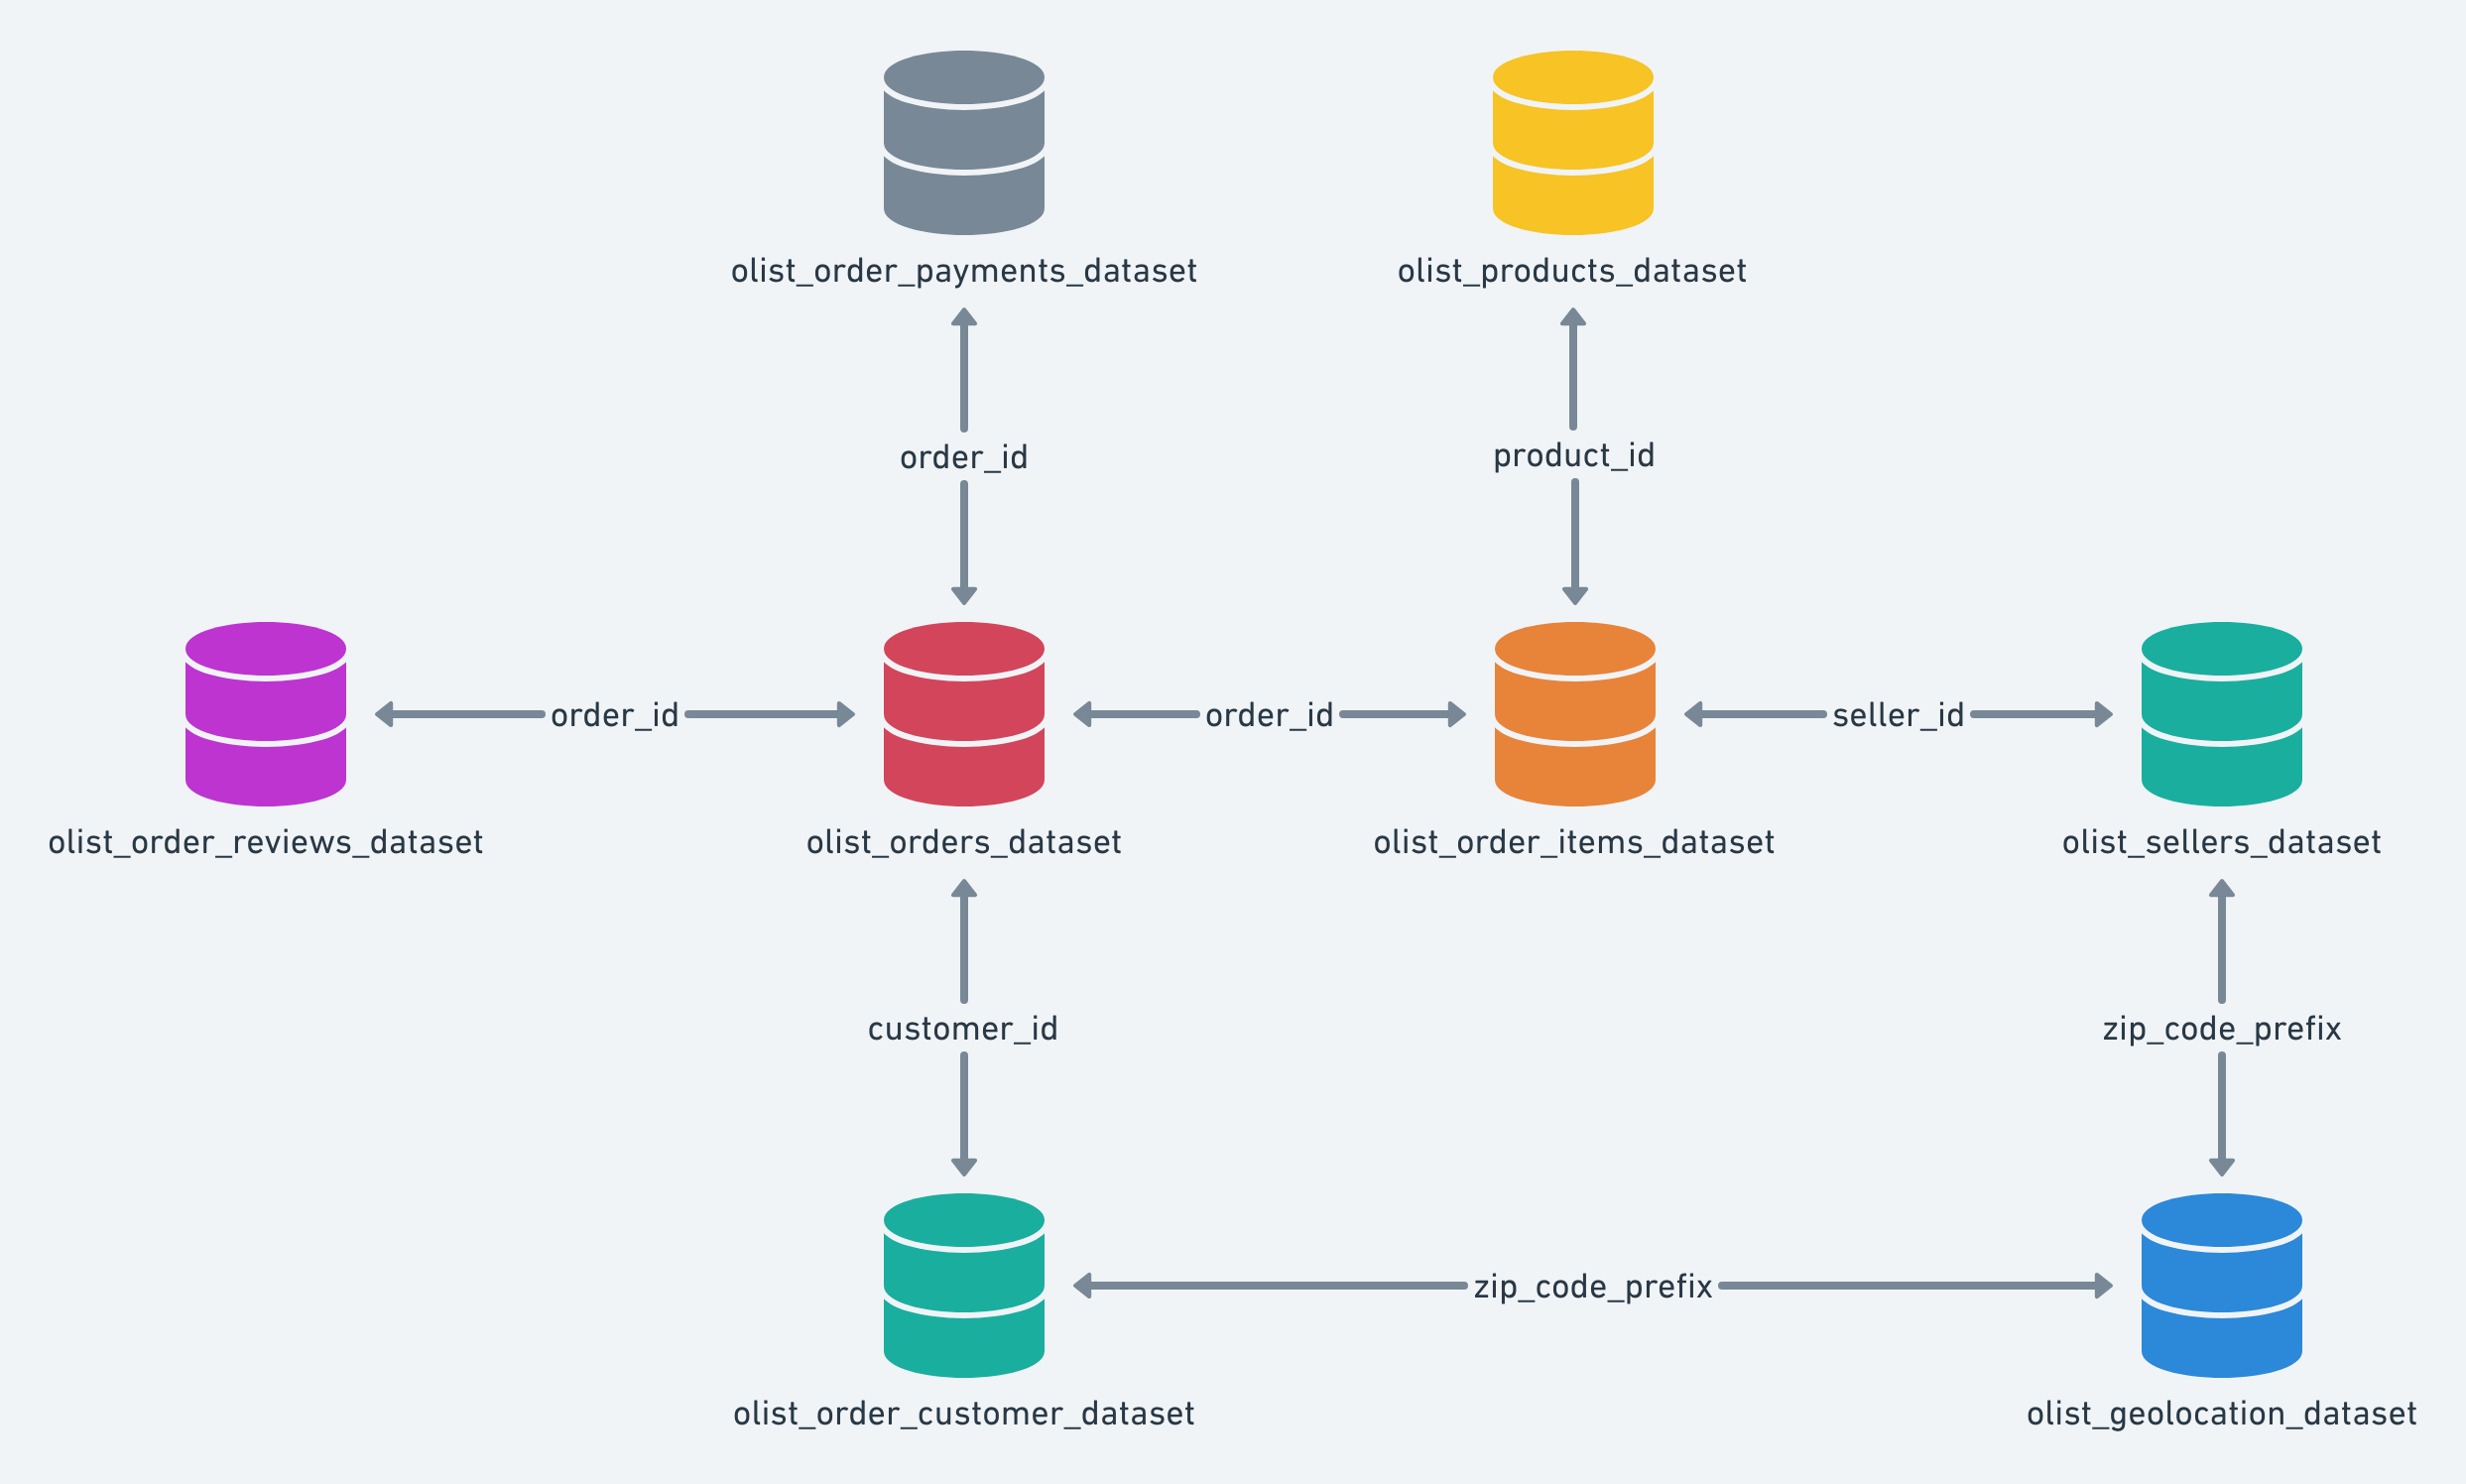

In [ ]:
!pip install unidecode
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from scipy import stats

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [ ]:
customers = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))
geolocation = pd.read_csv(os.path.join(path, 'olist_geolocation_dataset.csv'))
order_items = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))
order_payments = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv'))
order_reviews = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))
orders = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))
products = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))
sellers = pd.read_csv(os.path.join(path, 'olist_sellers_dataset.csv'))
product_category_name_translation = pd.read_csv(os.path.join(path, 'product_category_name_translation.csv'))

## Customers
This dataset contains information about customers and their locations.

Columns:
- **customer_id** - customer ID, unique for each order (used to join with the orders table).
- **customer_unique_id** - unique ID of each customer.
- **customer_zip_code_prefix** - first 5 digits of the customer's zip code; serves as a key to join with the geolocation table.
- **customer_city** - customer's city.
- **customer_state** - customer's state.

In [ ]:
customers.shape

(99441, 5)

In [ ]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [ ]:
customers.duplicated().sum()

np.int64(0)

0 null entries. No duplicates found.

Let's take a closer look at the customer_city column and clean up inconsistent entries.

In [ ]:
cities_count = len(customers['customer_city'].unique())
print(cities_count)

4119


In [ ]:
import re
import unidecode

# function for cleaning most common problems
def normalize_city(name):
  name = str(name).strip().lower()
  name = unidecode.unidecode(name) # strips accents: 'são paulo' -> 'sao paulo'
  name = re.sub(r'[^a-z0-9\s\'-]', '', name) # drop stray punctuation/junk like trailing ", brasil"
  name = re.sub(r"[-']", " ", name) # replacing - with spaces
  name = re.sub(r'\s+', ' ', name).strip()
  return name

customers['customer_city'] = customers['customer_city'].apply(normalize_city)
cities = np.sort(np.array(customers['customer_city'].unique()))
print(len(cities))

4113


## Geolocation
This dataset contains Brazilian zip code prefixes and their latitude/longitude coordinates.

Columns:
- **geolocation_zip_code_prefix** - first 5 digits of the zip code; serves as a key to join with the customers table.
- **geolocation_lat** - latitude of the zip code prefix.
- **geolocation_lng** - longitude of the zip code prefix.
- **geolocation_city** - city.
- **geolocation_state** - state.

Since city and state are already available in the customers table, we will not use this table.

## Order Items
This dataset contains information about the items purchased within each order.

Columns:
- **order_id** - unique order ID.
- **order_item_id** - sequential number of the item within the same order.
- **product_id** - unique product ID.
- **seller_id** - unique seller ID.
- **shipping_limit_date** - the date by which the seller must hand the order over to the logistics partner.
- **price** - item price.
- **freight_value** - item freight value (if an order has more than one item, the freight value is split between the items).

In [ ]:
order_items.shape

(112650, 7)

In [ ]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [ ]:
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])

In [ ]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


In [ ]:
order_items.duplicated().sum()

np.int64(0)

In [ ]:
order_items[['price', 'freight_value']].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


0 null entries. No duplicates found.

## Order Payments
This dataset contains information about the payment options used for orders.

Columns:
- **order_id** - unique order ID.
- **payment_sequential** - sequential number of the payment method used for the order (an order can be paid with several methods).
- **payment_type** - payment method chosen by the customer.
- **payment_installments** - number of installments chosen by the customer.
- **payment_value** - transaction value.

In [ ]:
order_payments.shape

(103886, 5)

In [ ]:
order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
order_payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [ ]:
order_payments.duplicated().sum()

np.int64(0)

In [ ]:
order_payments.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [ ]:
order_payments[order_payments['payment_installments'] == 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


0 null entries. No duplicates found. The payment_value column contains outliers (the maximum value of 13,664 is far above the upper IQR bound), which are likely caused by unusually large purchases.

The payment_installments column also contains anomalous values: 0 installments. Since a payment cannot be split into 0 installments, these entries need to be fixed. There are only 2 such entries, so I replaced them with 1.

In [ ]:
order_payments['payment_installments'] = order_payments['payment_installments'].replace(0, 1)

## Order Reviews
This dataset contains information about the reviews left by customers.

Columns:
- **review_id** - unique review ID.
- **order_id** - unique order ID.
- **review_score** - score from 1 to 5 given by the customer in a satisfaction survey.
- **review_comment_title** - title of the review comment, in Portuguese.
- **review_comment_message** - review comment message, in Portuguese.
- **review_creation_date** - date when the satisfaction survey was sent to the customer.
- **review_answer_timestamp** - timestamp of the customer's survey answer.

In [ ]:
order_reviews.shape

(99224, 7)

In [ ]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
order_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
order_reviews['review_creation_date'] = pd.to_datetime(order_reviews['review_creation_date'])
order_reviews['review_answer_timestamp'] = pd.to_datetime(order_reviews['review_answer_timestamp'])

In [ ]:
order_reviews.duplicated().sum()

np.int64(0)

The review_comment_title and review_comment_message columns contain null values because leaving a comment or a title is optional. We fill these nulls with neutral values: 'No title' and 'No comment'.

In [ ]:
order_reviews['review_comment_title'] = order_reviews['review_comment_title'].fillna('No title')
order_reviews['review_comment_message'] = order_reviews['review_comment_message'].fillna('No comment')
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,No title,No comment,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,No title,No comment,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,No title,No comment,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,No title,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,No title,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


## Orders
The core dataset, which contains information about orders.

Columns:
- **order_id** - unique order ID.
- **customer_id** - key to the customers dataset. Each order has a unique customer_id.
- **order_status** - order status (delivered, shipped, etc.).
- **order_purchase_timestamp** - purchase timestamp.
- **order_approved_at** - payment approval timestamp.
- **order_delivered_carrier_date** - timestamp when the order was handed over to the logistics partner.
- **order_delivered_customer_date** - actual delivery date to the customer.
- **order_estimated_delivery_date** - estimated delivery date shown to the customer at the moment of purchase.

In [ ]:
orders.shape

(99441, 8)

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
orders.loc[
    orders["order_approved_at"].isna(),
    "order_status"
].value_counts()

,count
order_status,
canceled,141
delivered,14
created,5


In [ ]:
orders.loc[
    orders["order_delivered_carrier_date"].isna(),
    "order_status"
].value_counts()

,count
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,2


In [ ]:
orders.loc[
    orders["order_delivered_customer_date"].isna(),
    "order_status"
].value_counts()

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


In [ ]:
orders.duplicated().sum()

np.int64(0)

The **order_approved_at**, **order_delivered_carrier_date**, and **order_delivered_customer_date** columns contain missing values. Nulls occur when an order is canceled, the payment is rejected, a data entry error occurs, or the order has not reached that processing stage yet. These missing values should therefore be closely related to the **order_status** column, so we will not drop them.

No duplicates found.

In [ ]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders[date_columns] = orders[date_columns].apply(pd.to_datetime)

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


## Products
This dataset contains information about the products sold on Olist.

Columns:
- **product_id** - unique product ID.
- **product_category_name** - root category of the product, in Portuguese.
- **product_name_lenght** - number of characters in the product name (the column name is misspelled in the original dataset).
- **product_description_lenght** - number of characters in the product description (also misspelled in the original dataset).
- **product_photos_qty** - number of published product photos.
- **product_weight_g** - product weight in grams.
- **product_length_cm** - product length in centimeters.
- **product_height_cm** - product height in centimeters.
- **product_width_cm** - product width in centimeters.

In [ ]:
products.shape

(32951, 9)

In [ ]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [ ]:
products.duplicated().sum()

np.int64(0)

Every column except product_id contains null values.

The product_category_name, product_name_lenght, product_description_lenght, and product_photos_qty columns each have 610 null values, which may be caused by manual or system errors when adding a product: the product_id was created, but no additional information was provided.

As for the product_weight_g, product_length_cm, product_height_cm, and product_width_cm columns, exactly 2 products are missing physical dimensions, which is likely due to isolated data entry errors.

To preserve the integrity of the transaction data, missing categories are imputed as 'unknown' rather than dropped.

In [ ]:
products['product_category_name'] = products['product_category_name'].fillna('unknown')
products['product_name_lenght'] = products['product_name_lenght'].fillna(0)
products['product_description_lenght'] = products['product_description_lenght'].fillna(0)
products['product_photos_qty'] = products['product_photos_qty'].fillna(0)

cols_logistics = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for col in cols_logistics:
    products[col] = products[col].fillna(products[col].median())

## Sellers
This dataset contains information about the sellers who fulfilled orders on Olist.

Columns:
- **seller_id** - unique seller ID.
- **seller_zip_code_prefix** - first 5 digits of the seller's zip code.
- **seller_city** - seller's city.
- **seller_state** - seller's state.

In [ ]:
sellers.shape

(3095, 4)

In [ ]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [ ]:
sellers.duplicated().sum()

np.int64(0)

0 null entries. No duplicates found.

## Product Category Name Translation

Contains the translation of product_category_name into English.

In [ ]:
product_category_name_translation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


0 null values.

In [ ]:
products_english = pd.merge(products, product_category_name_translation, on='product_category_name', how='left')
products_english

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares
...,...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0,furniture_decor
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0,construction_tools_lights
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0,bed_bath_table
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0,computers_accessories


In [ ]:
products_nan = products_english[products_english['product_category_name_english'].isna()][['product_category_name', 'product_category_name_english']]

manual_translations = {
    'pc_gamer': 'pc_gamer',
    'portateis_cozinha_e_preparadores_de_alimentos': 'kitchen_portables_and_food_preparers',
    'unknown': 'unknown'
}

products_english['product_category_name_english'] = products_english['product_category_name_english'].fillna(
    products_english['product_category_name'].map(manual_translations)
)

products_english.isna().sum()


,0
product_id,0
product_category_name,0
product_name_lenght,0
product_description_lenght,0
product_photos_qty,0
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0
product_category_name_english,0


# Data Integration


In [ ]:
# delivery time
orders['delivery_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.days

# approval time
orders['approval_time'] = orders['order_approved_at'] - orders['order_purchase_timestamp']

# shipping time
orders['shipping_time'] = orders['order_delivered_carrier_date'] - orders['order_approved_at']

# delivery delay in calendar days (delivery date - estimated delivery date)
# the estimated date has no time of day (00:00:00), so the delivery timestamp is rounded down to the date;
# otherwise an order delivered on the promised day would be counted as late
orders['delivery_delay'] = orders['order_delivered_customer_date'].dt.normalize() - orders['order_estimated_delivery_date']

# order aggregation
orders_revenue = pd.merge(orders, order_items, how='left', on='order_id')
orders_revenue = (
    orders_revenue
    .groupby('order_id', as_index=False)
    .agg(
        total_order_value = ('price', 'sum'),
        total_freight = ('freight_value', 'sum'),
        number_of_items = ('product_id', 'count'),
    )
)

orders_revenue = orders_revenue.merge(
    orders[
        [
            "order_id",
            "customer_id",
            "order_purchase_timestamp",
            "order_status",
            "delivery_days",
            "shipping_time",
            "approval_time",
            "delivery_delay"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
).merge(customers[
    [
        'customer_id',
        'customer_unique_id'
    ]
],
    on='customer_id',
    how='left')

In [ ]:
orders_revenue.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype          
---  ------                    --------------  -----          
 0   order_id                  99441 non-null  object         
 1   total_order_value         99441 non-null  float64        
 2   total_freight             99441 non-null  float64        
 3   number_of_items           99441 non-null  int64          
 4   customer_id               99441 non-null  object         
 5   order_purchase_timestamp  99441 non-null  datetime64[ns] 
 6   order_status              99441 non-null  object         
 7   delivery_days             96476 non-null  float64        
 8   shipping_time             97644 non-null  timedelta64[ns]
 9   approval_time             99281 non-null  timedelta64[ns]
 10  delivery_delay            96476 non-null  timedelta64[ns]
 11  customer_unique_id        99441 non-null  object         
dtypes: d

In [ ]:
orders_revenue.head(20)

,order_id,total_order_value,total_freight,number_of_items,customer_id,order_purchase_timestamp,order_status,delivery_days,shipping_time,approval_time,delivery_delay,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,delivered,7.0,6 days 08:48:41,0 days 00:46:33,-9 days,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,delivered,16.0,8 days 03:29:47,0 days 00:12:07,-3 days,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,delivered,7.0,1 days 21:48:18,0 days 00:14:59,-14 days,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,delivered,6.0,2 days 03:17:42,0 days 00:09:43,-6 days,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,delivered,25.0,11 days 19:35:56,0 days 00:12:22,-16 days,64b576fb70d441e8f1b2d7d446e483c5
5,00048cc3ae777c65dbb7d2a0634bc1ea,21.90,12.69,1,816cbea969fe5b689b39cfc97a506742,2017-05-15 21:42:34,delivered,6.0,0 days 07:10:28,1 days 06:12:53,-15 days,85c835d128beae5b4ce8602c491bf385
6,00054e8431b9d7675808bcb819fb4a32,19.90,11.85,1,32e2e6ab09e778d99bf2e0ecd4898718,2017-12-10 11:53:48,delivered,8.0,1 days 12:57:17,0 days 00:16:43,-17 days,635d9ac1680f03288e72ada3a1035803
7,000576fe39319847cbb9d288c5617fa6,810.00,70.75,1,9ed5e522dd9dd85b4af4a077526d8117,2018-07-04 12:08:27,delivered,5.0,-1 days +19:39:12,1 days 04:27:21,-16 days,fda4476abb6307ab3c415b7e6d026526
8,0005a1a1728c9d785b8e2b08b904576c,145.95,11.65,1,16150771dfd4776261284213b89c304e,2018-03-19 18:40:33,delivered,9.0,7 days 06:02:21,0 days 23:54:48,0 days,639d23421f5517f69d0c3d6e6564cf0e
9,0005f50442cb953dcd1d21e1fb923495,53.99,11.40,1,351d3cb2cee3c7fd0af6616c82df21d3,2018-07-02 13:59:39,delivered,2.0,1 days 00:14:04,0 days 00:11:17,-19 days,0782c41380992a5a533489063df0eef6


In [ ]:
customers_data = pd.merge(customers, orders_revenue, how='left', on='customer_id')
customers_data.head()

,customer_id,customer_unique_id_x,customer_zip_code_prefix,customer_city,customer_state,order_id,total_order_value,total_freight,number_of_items,order_purchase_timestamp,order_status,delivery_days,shipping_time,approval_time,delivery_delay,customer_unique_id_y
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,124.99,21.88,1,2017-05-16 15:05:35,delivered,8.0,6 days 19:25:45,0 days 00:16:37,-11 days,861eff4711a542e4b93843c6dd7febb0
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,289.00,46.48,1,2018-01-12 20:48:24,delivered,16.0,2 days 20:16:27,0 days 00:10:08,-8 days,290c77bc529b7ac935b93aa66c333dc3
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,139.94,17.79,1,2018-05-19 16:07:45,delivered,26.0,21 days 22:11:50,1 days 00:11:25,1 days,060e732b5b29e8181a18229c7b0b2b5e
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,149.94,23.36,1,2018-03-13 16:06:38,delivered,14.0,14 days 05:53:23,0 days 01:22:41,-13 days,259dac757896d24d7702b9acbbff3f3c
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,230.00,22.25,1,2018-07-29 09:51:30,delivered,11.0,1 days 05:05:51,0 days 00:18:39,-6 days,345ecd01c38d18a9036ed96c73b8d066


In [ ]:
product_data = (
    order_items[[
        'order_id',
        'product_id',
        'seller_id',
        'price',
        'freight_value'
    ]]
    .merge(products_english[[
        'product_id',
        'product_category_name_english'
    ]],
           on='product_id',
           how='left')
)

product_data.head()

,order_id,product_id,seller_id,price,freight_value,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14,garden_tools


# Exploratory Analysis


## Sales Analysis
### Business Question:
How is the marketplace performing?

**KPI:**
- Gross Merchandise Value (GMV)
- Total Orders
- Average Order Value
- Average Items per Order
- Average Freight per Order
- Freight Share
- Average Approval Time
- Average Shipping Time
- Average Delivery Time
- On-Time Delivery Rate
- Late Delivery Rate

#### **Sales Overview**

In [ ]:
# keeping only orders with 'delivered' status (to analyze the value of orders that were actually completed)
orders_revenue_all_statuses = orders_revenue
orders_revenue = orders_revenue[orders_revenue['order_status'] == 'delivered'].copy()

# main KPIs evaluation
total_revenue = orders_revenue['total_order_value'].sum()
total_orders_count = orders_revenue['order_id'].nunique()
average_order_value = orders_revenue['total_order_value'].mean()
median_order_value = orders_revenue['total_order_value'].median()
average_items_per_order = orders_revenue['number_of_items'].mean()
average_freight_per_order = orders_revenue['total_freight'].mean()
order_purchase_time_range = orders_revenue['order_purchase_timestamp'].max() - orders_revenue['order_purchase_timestamp'].min()

print(f'Total Revenue (GMV): R${total_revenue:.2f}')
print(f'Total Orders Count: {total_orders_count}')
print(f'Average Value per Order: R${average_order_value:.2f}')
print(f'Median Value per Order: R${median_order_value:.2f}')
print(f'Average Items per Order: {average_items_per_order:.2f}')
print(f'Average Freight per Order: R${average_freight_per_order:.2f}')
print(f'Order Purchase Time Range: {order_purchase_time_range}')

Total Revenue (GMV): R$13221498.11
Total Orders Count: 96478
Average Value per Order: R$137.04
Median Value per Order: R$86.57
Average Items per Order: 1.14
Average Freight per Order: R$22.79
Order Purchase Time Range: 713 days 02:43:59


##### Revenue Distribution Histogram

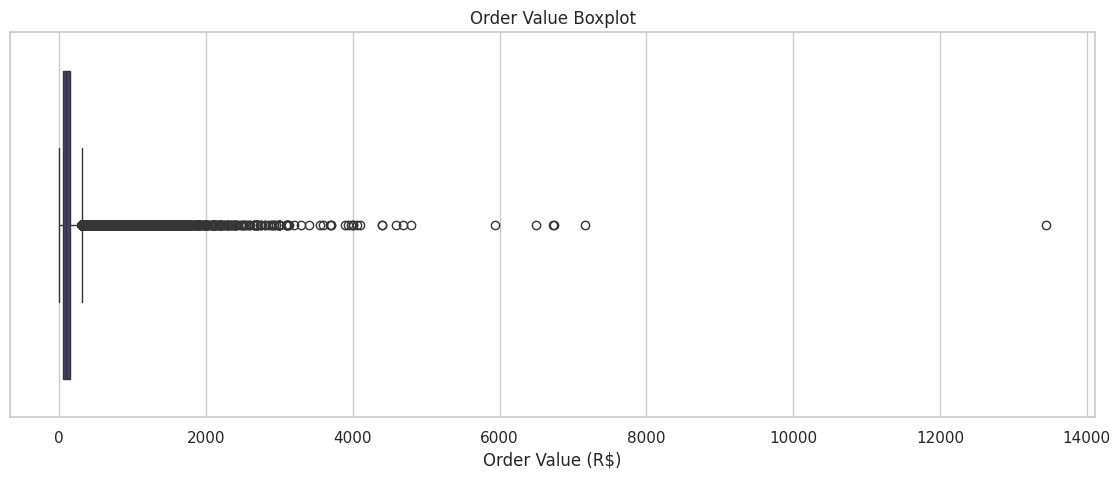

In [ ]:
sns.set_theme(style="whitegrid", palette="viridis")
viridis_colors = sns.color_palette('viridis', 10)
plt.figure(figsize=(14, 5))
sns.boxplot(data=orders_revenue, x='total_order_value')
plt.title('Order Value Boxplot')
plt.xlabel('Order Value (R$)')
plt.show()

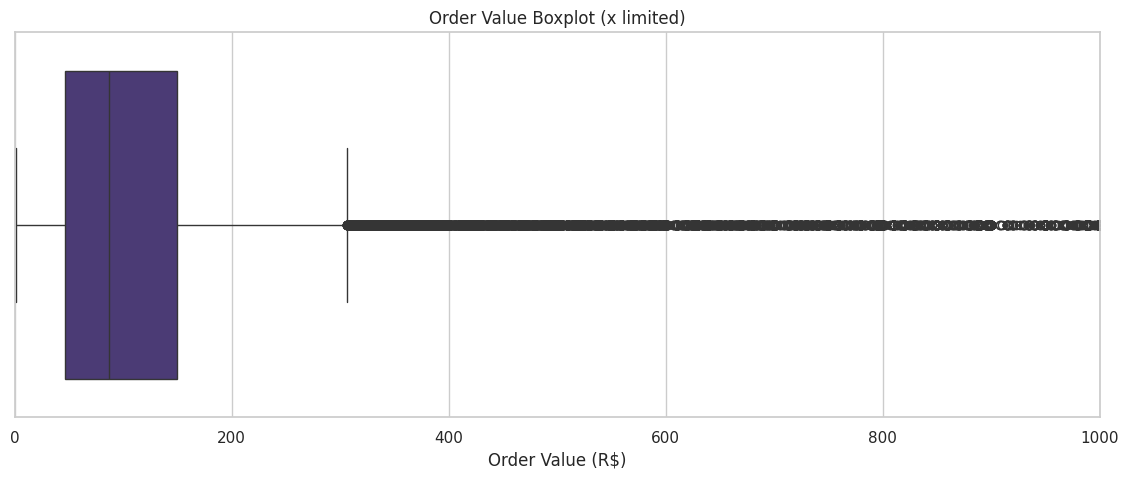

In [ ]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=orders_revenue, x='total_order_value')
plt.xlim(0, 1000)
plt.title('Order Value Boxplot (x limited)')
plt.xlabel('Order Value (R$)')
plt.show()

In [ ]:
Q1 = orders_revenue['total_order_value'].quantile(0.25)
Q3 = orders_revenue['total_order_value'].quantile(0.75)
IQR = Q3 - Q1

print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')

Q1: 45.9
Q3: 149.9
IQR: 104.0


The middle 50% of orders (the interquartile range) are worth between R\$ 45.90 and R\$ 149.90. Orders above R\$ 305.90 (the upper IQR bound) are statistical outliers and make up 7.94% of all orders. Given the very low repeat purchase rate (see Customer Analysis), these high-value orders are more likely driven by expensive product categories than by a group of VIP customers, so it makes sense to analyze them separately from typical orders.

In [ ]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

orders_without_outliers = orders_revenue[
    (orders_revenue['total_order_value'] >= max(0, lower_bound)) &
    (orders_revenue['total_order_value'] <= upper_bound)]

outliers = orders_revenue[orders_revenue['total_order_value'] > upper_bound]

average_order_value_without_outliers = orders_without_outliers['total_order_value'].mean()
average_outlier_order_value = outliers['total_order_value'].mean()
median_order_value_without_outliers = orders_without_outliers['total_order_value'].median()
median_outlier_order_value = outliers['total_order_value'].median()
average_items_per_order_common = orders_without_outliers['number_of_items'].mean()
median_items_per_order_common = orders_without_outliers['number_of_items'].median()
average_items_per_order_outliers = outliers['number_of_items'].mean()
median_items_per_order_outliers = outliers['number_of_items'].median()

print(f'Number of Data without Outliers: {len(orders_without_outliers)}')
print(f'Number of Outliers: {len(outliers)}')
print(f'Average Order Value (without outliers): R$ {average_order_value_without_outliers:.2f}')
print(f'Average Order Value (outliers): R$ {average_outlier_order_value:.2f}')
print(f'Median Order Value (without outliers): R$ {median_order_value_without_outliers:.2f}')
print(f'Median Order Value (outliers): R$ {median_outlier_order_value:.2f}')
print(f'Average items per order (without outliers): {average_items_per_order_common:.2f}')
print(f'Median items per order (without outliers): {median_items_per_order_common:.0f}')
print(f'Average items per order (outliers): {average_items_per_order_outliers:.2f}')
print(f'Median items per order (outliers): {median_items_per_order_outliers:.0f}')

print(f'Outliers Share: {len(outliers) / len(orders_revenue) * 100:.2f}%')

Number of Data without Outliers: 88819
Number of Outliers: 7659
Average Order Value (without outliers): R$ 94.34
Average Order Value (outliers): R$ 632.22
Median Order Value (without outliers): R$ 79.00
Median Order Value (outliers): R$ 478.70
Average items per order (without outliers): 1.12
Median items per order (without outliers): 1
Average items per order (outliers): 1.40
Median items per order (outliers): 1
Outliers Share: 7.94%


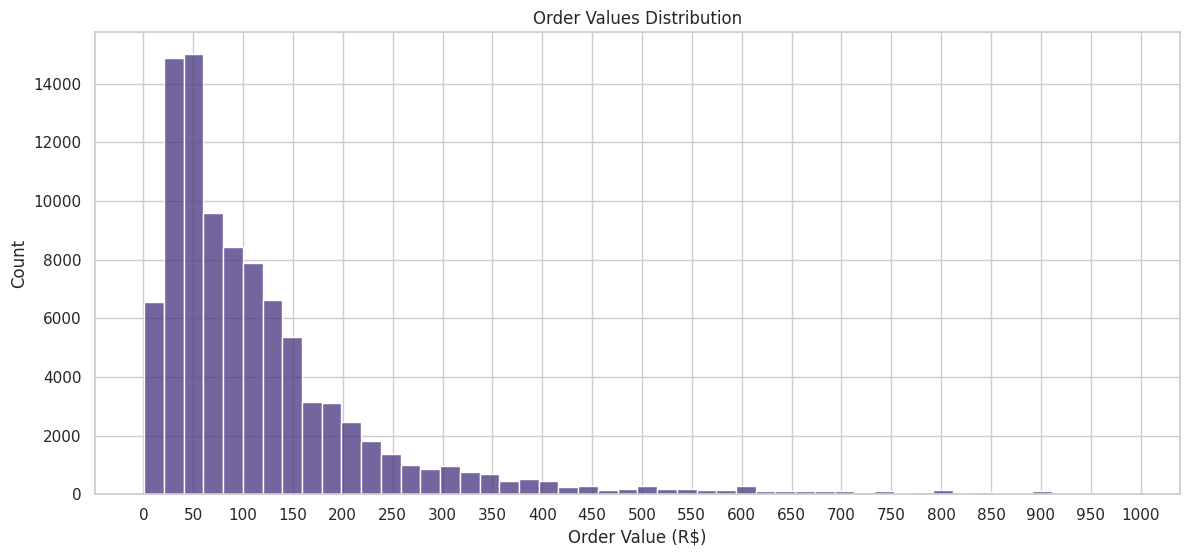

In [ ]:
# since our total_order_value data has huge outliers we should limit it by 0.99 percentile
limit = orders_revenue['total_order_value'].quantile(0.99)
histplot_data = orders_revenue[orders_revenue['total_order_value'] < limit]

plt.figure(figsize=(14, 6))
sns.histplot(data=histplot_data, x='total_order_value', bins=50)
plt.xticks(np.arange(0, 1001, 50))
plt.title('Order Values Distribution')
plt.xlabel('Order Value (R$)')
plt.show()

Over about 713 days, delivered orders generated **R\$ 13.22M in gross merchandise value (GMV)**: the total price of items sold by sellers, excluding freight (referred to as revenue in the charts below). This is not Olist's own revenue. As a marketplace, Olist earns a share of it through fees charged to sellers.

The average order value (AOV) is R\$ 137.04, while the median is R\$ 86.57, so the distribution is right-skewed, as the histogram confirms. Typical orders (without outliers) have an average of R\$ 94.34 and a median of R\$ 79. Outlier orders have an average of about R\$ 632 and a median of about R\$ 479. Both segments are still right-skewed, so the median describes a typical order better than the average.

#### **Revenue Trend**

In [ ]:
orders_revenue['order_month'] = orders_revenue['order_purchase_timestamp'].dt.to_period('M')

monthly_summary = orders_revenue.groupby('order_month').agg(
    total_revenue=('total_order_value', 'sum'),
    orders_count=('order_id', 'nunique'),
    customers_amount=('customer_unique_id', 'nunique')
).reset_index()

monthly_summary['average_order_value'] = monthly_summary['total_revenue'] / monthly_summary['orders_count']
monthly_summary['revenue_per_customer'] = monthly_summary['total_revenue'] / monthly_summary['customers_amount']

monthly_summary['monthly_revenue_growth_pct'] = monthly_summary['total_revenue'].pct_change() * 100
monthly_summary['order_growth_pct'] = monthly_summary['orders_count'].pct_change() * 100

# filling NA, since the first row is always NA
monthly_summary[['monthly_revenue_growth_pct', 'order_growth_pct']] = monthly_summary[['monthly_revenue_growth_pct', 'order_growth_pct']].fillna(0)

pd.set_option('display.float_format', '{:.5f}'.format)

monthly_summary

,order_month,total_revenue,orders_count,customers_amount,average_order_value,revenue_per_customer,monthly_revenue_growth_pct,order_growth_pct
0,2016-09,134.97000,1,1,134.97000,134.97000,0.00000,0.00000
1,2016-10,40325.11000,265,262,152.17023,153.91263,29777.09121,26400.00000
2,2016-12,10.90000,1,1,10.90000,10.90000,-99.97297,-99.62264
3,2017-01,111798.36000,750,718,149.06448,155.70802,1025573.02752,74900.00000
4,2017-02,234223.40000,1653,1630,141.69595,143.69534,109.50522,120.40000
5,2017-03,359198.85000,2546,2508,141.08360,143.22123,53.35737,54.02299
6,2017-04,340669.68000,2303,2274,147.92431,149.81077,-5.15847,-9.54438
7,2017-05,489338.25000,3546,3479,137.99725,140.65486,43.64009,53.97308
8,2017-06,421923.37000,3135,3076,134.58481,137.16625,-13.77674,-11.59052
9,2017-07,481604.52000,3872,3802,124.38133,126.67136,14.14502,23.50877


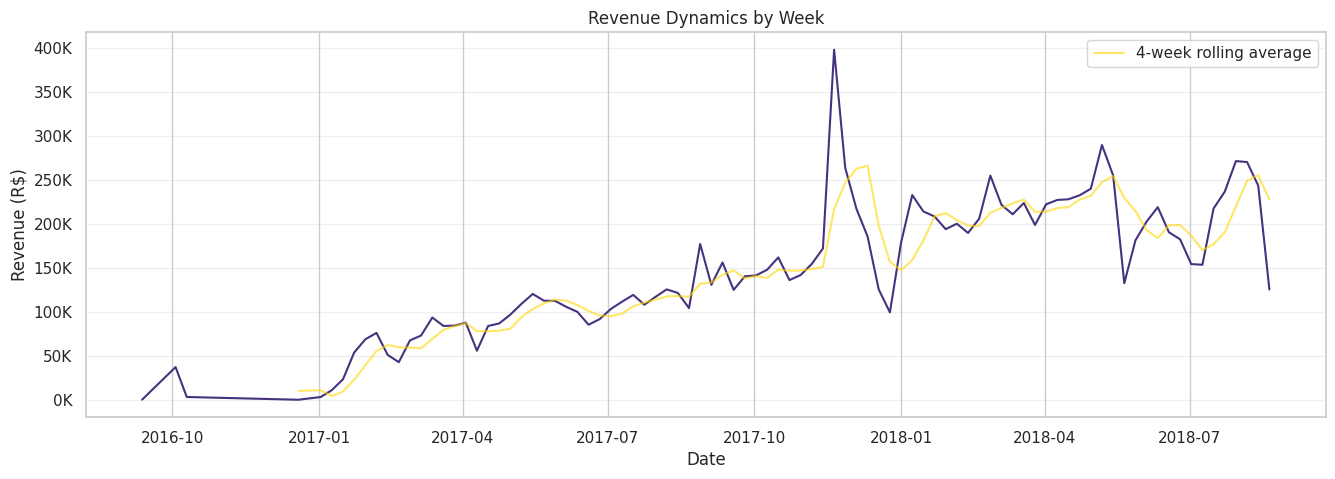

In [ ]:
from matplotlib.ticker import FuncFormatter
orders_revenue['order_week'] = orders_revenue['order_purchase_timestamp'].dt.to_period('W')

orders_revenue_by_week = orders_revenue.groupby('order_week').agg(
    total_revenue=('total_order_value', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

orders_revenue_by_week['order_week'] = orders_revenue_by_week['order_week'].dt.to_timestamp()

last_week = orders_revenue_by_week['order_week'].max()
orders_revenue_by_week = orders_revenue_by_week[orders_revenue_by_week['order_week'] < last_week]

# function for y-ticks format
def format_k(x, pos):
  return f'{x / 1000:g}K'

plt.figure(figsize=(16, 5))
sns.lineplot(data=orders_revenue_by_week, x='order_week', y='total_revenue')

window_size = 4
rolling_avg = orders_revenue_by_week['total_revenue'].rolling(window=window_size).mean()

sns.lineplot(x=orders_revenue_by_week['order_week'], y=rolling_avg, color='gold', alpha=0.6, label='4-week rolling average')
plt.gca().yaxis.set_major_formatter(FuncFormatter(format_k))
plt.grid(True, axis='y', alpha=0.3)
plt.title('Revenue Dynamics by Week')
plt.xlabel('Date')
plt.ylabel('Revenue (R$)')
plt.show()

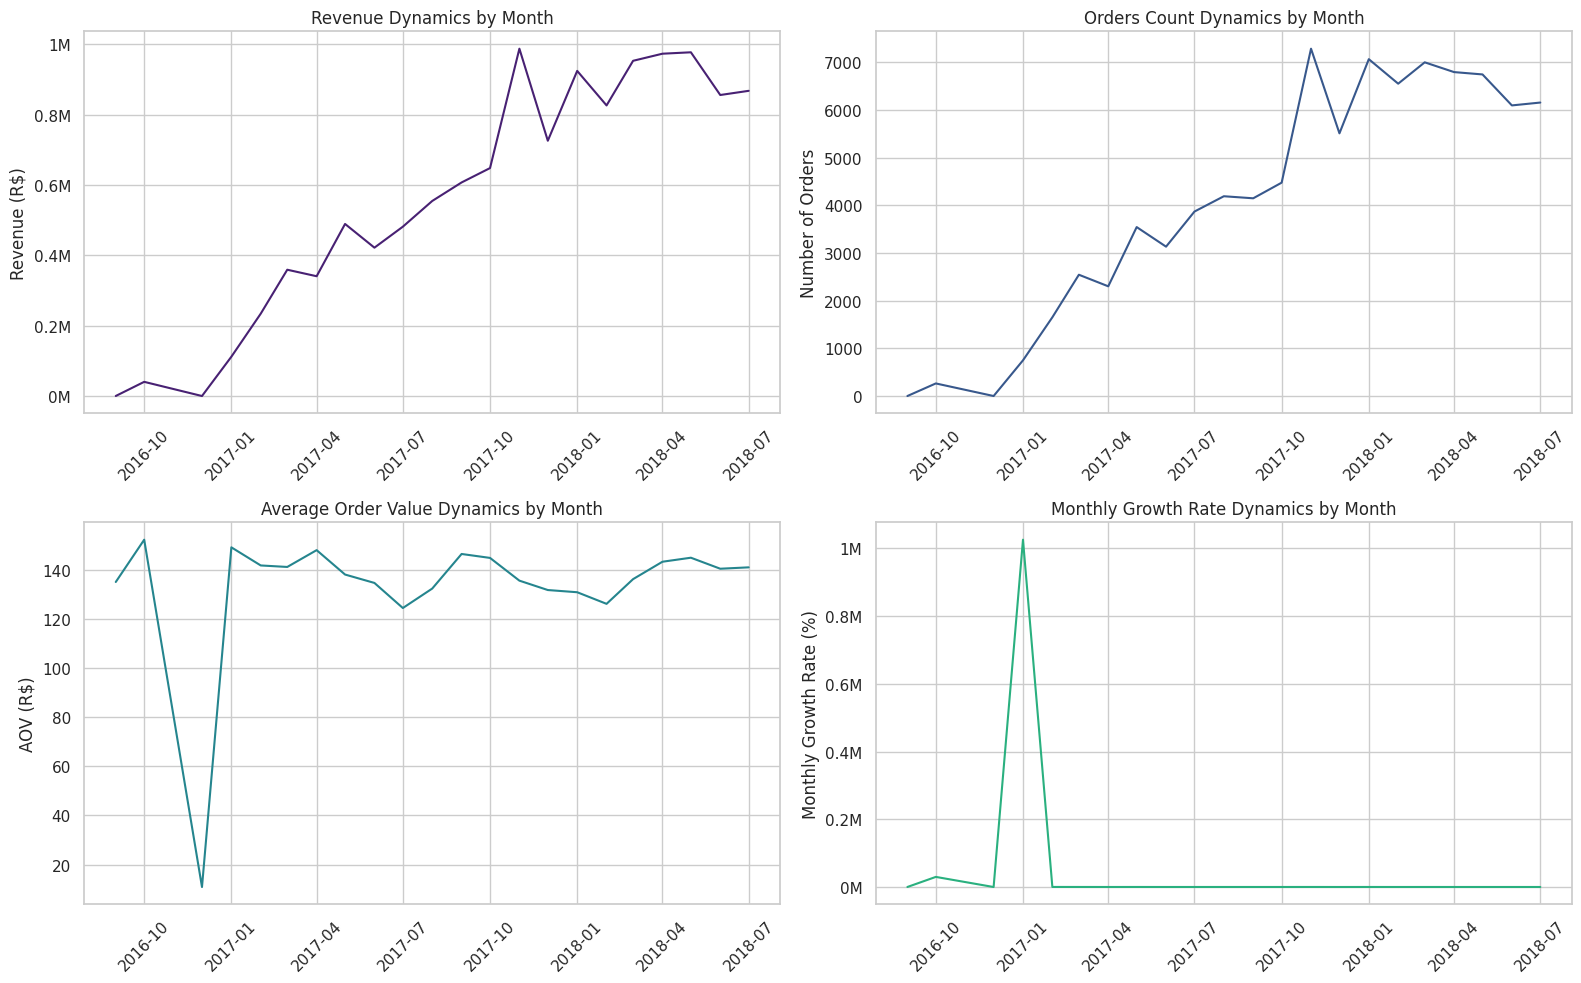

In [ ]:
def format_m(x, pos):
  return f'{x / 1000000:g}M'

# last month is excluded because it's a partial period
last_month = monthly_summary['order_month'].max()
monthly_summary = monthly_summary[monthly_summary['order_month'] < last_month].copy()

fig, ax = plt.subplots(2, 2, figsize=(16, 10))

# total revenue dynamics by month
monthly_summary['order_month'] = monthly_summary['order_month'].dt.to_timestamp()
sns.lineplot(data=monthly_summary, x='order_month', y='total_revenue', ax=ax[0, 0], color=viridis_colors[0])

ax[0, 0].yaxis.set_major_formatter(FuncFormatter(format_m))
ax[0, 0].set_title('Revenue Dynamics by Month')
ax[0, 0].set_xlabel('')
ax[0, 0].set_ylabel('Revenue (R$)')
ax[0, 0].tick_params(axis='x', rotation=45)


# orders count dynamics by month
sns.lineplot(data=monthly_summary, x='order_month', y='orders_count', ax=ax[0, 1], color=viridis_colors[2])
ax[0, 1].set_title('Orders Count Dynamics by Month')
ax[0, 1].set_xlabel('')
ax[0, 1].set_ylabel('Number of Orders')
ax[0, 1].tick_params(axis='x', rotation=45)


# average order value dynamics by month
sns.lineplot(data=monthly_summary, x='order_month', y='average_order_value', ax=ax[1, 0], color=viridis_colors[4])
ax[1, 0].set_title('Average Order Value Dynamics by Month')
ax[1, 0].set_xlabel('')
ax[1, 0].set_ylabel('AOV (R$)')
ax[1, 0].tick_params(axis='x', rotation=45)

# average order value dynamics by month
sns.lineplot(data=monthly_summary, x='order_month', y='monthly_revenue_growth_pct', ax=ax[1, 1], color=viridis_colors[6])
ax[1, 1].yaxis.set_major_formatter(FuncFormatter(format_m))
ax[1, 1].set_title('Monthly Growth Rate Dynamics by Month')
ax[1, 1].set_xlabel('')
ax[1, 1].set_ylabel('Monthly Growth Rate (%)')
ax[1, 1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


The marketplace shows strong growth from almost zero in late 2016 to roughly R\$ 0.83–0.98M of monthly revenue in January–July 2018. Growth is fastest during 2017, then flattens from late 2017 through mid-2018 into a steady trend (around R\$ 0.83–0.98M and 6,100–7,100 orders per month).

The weekly chart shows a big revenue spike to about R\$ 400K in November 2017, which is likely related to Black Friday (November 24, 2017). The spike is followed by a sudden fall to about R\$ 100K, which is most likely a pull-forward effect (customers bought earlier, during the sale) rather than a real collapse.

Apart from the Black Friday spike, the weekly chart shows a few other local peaks (May 2018 at about R\$ 290K and July–August 2018 at about R\$ 270K). These could be checked against known promotions or holidays, but none of them is as extreme as November 2017.

AOV stays stable from January 2017 through 2018, at around R\$ 125–150 per order.

The sharp drop at the end of August 2018 most likely reflects the end of the dataset rather than a real decline: orders placed shortly before the data was extracted had not been delivered yet, so they are excluded from the delivered-only figures.

#### **Order Composition**

In [ ]:
average_items_per_order = orders_revenue['number_of_items'].mean()
median_items_per_order = orders_revenue['number_of_items'].median()

print(f'Average Number of Items per Order: {average_items_per_order:.2f}')
print(f'Median Items per Order: {median_items_per_order}')

Average Number of Items per Order: 1.14
Median Items per Order: 1.0


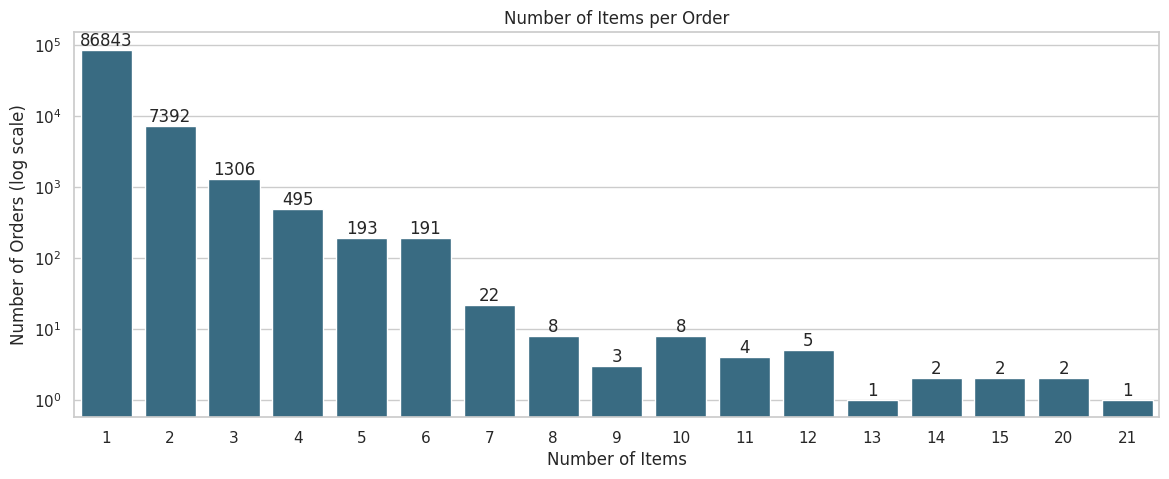

In [ ]:
items_counts = orders_revenue['number_of_items'].value_counts().sort_index()

plt.figure(figsize=(14, 5))
ax = sns.barplot(x=items_counts.index, y=items_counts.values, color=viridis_colors[3])
ax.bar_label(ax.containers[0], fmt='%d')  # exact number of orders above each bar
plt.yscale('log')  # log scale so the small multi-item groups stay visible next to the 1-item bar
plt.title('Number of Items per Order')
plt.xlabel('Number of Items')
plt.ylabel('Number of Orders (log scale)')
plt.show()

Most orders contain a single item (1.14 items per order on average, median 1). Orders with 2 or more items are much less common, and their share drops quickly as the number of items grows (the exact number of orders for each item count is shown above the bars). Only a handful of orders contain more than 12 items (the largest has 21).

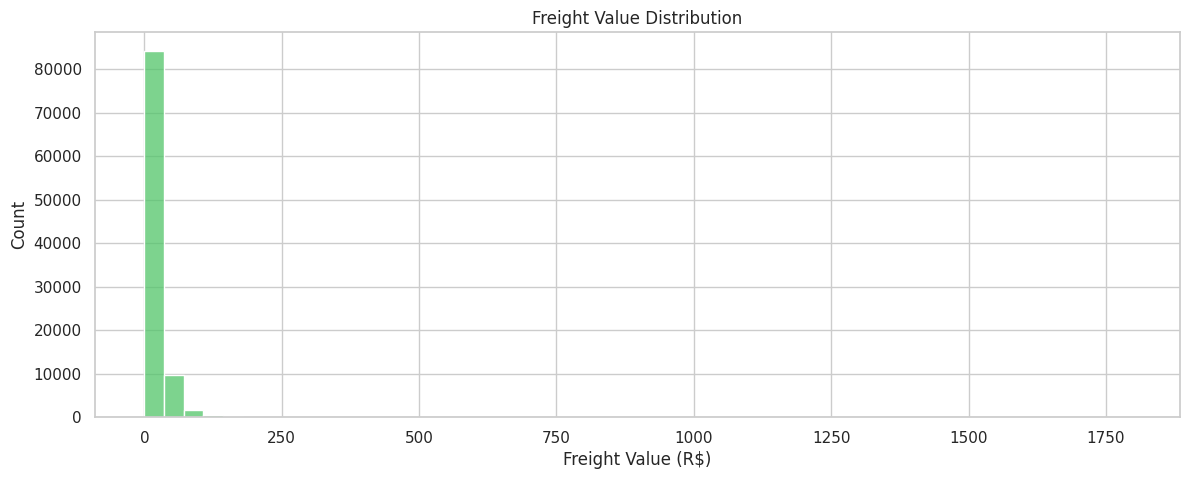

In [ ]:
plt.figure(figsize=(14, 5))
sns.histplot(data=orders_revenue, x='total_freight', bins=50, color=viridis_colors[7])
plt.title('Freight Value Distribution')
plt.xlabel('Freight Value (R$)')
plt.show()

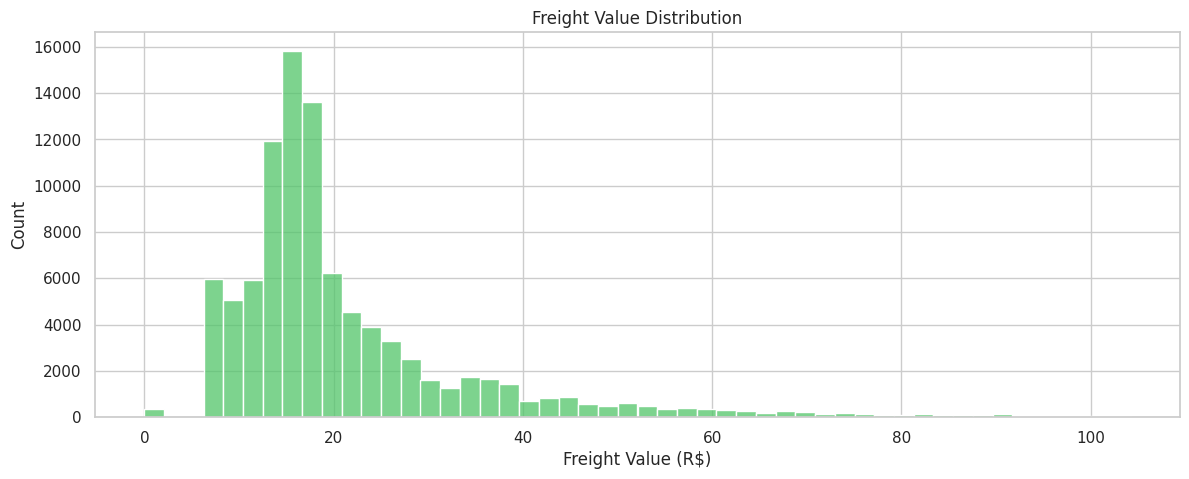

In [ ]:
# isolating average datapoints from outliers
limit = orders_revenue['total_freight'].quantile(0.99)
histplot_data = orders_revenue[orders_revenue['total_freight'] < limit]


plt.figure(figsize=(14, 5))
sns.histplot(data=histplot_data, x='total_freight', bins=50, color=viridis_colors[7])
plt.title('Freight Value Distribution')
plt.xlabel('Freight Value (R$)')
plt.show()

Freight values are right-skewed, just like order values. Let's check the correlation between the two metrics.

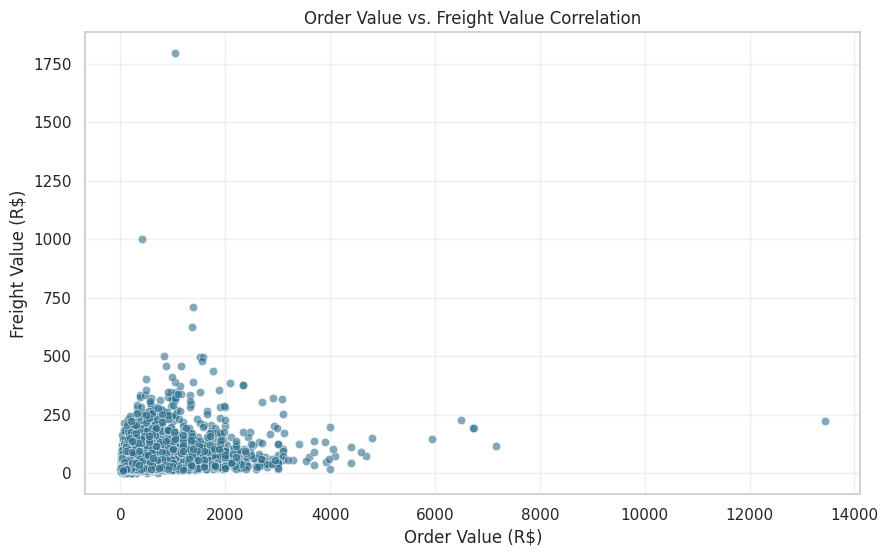

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=orders_revenue, x='total_order_value', y='total_freight', alpha=0.6, color=viridis_colors[3])
plt.title('Order Value vs. Freight Value Correlation')
plt.xlabel('Order Value (R$)')
plt.ylabel('Freight Value (R$)')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# checking the metrics data distribution before calculating the correlation coefficient
orders_stats, orders_pvalue = stats.shapiro(orders_revenue['total_order_value'])
freight_stats, freight_pvalue = stats.shapiro(orders_revenue['total_freight'])

print(f'Orders Value P-value: {orders_pvalue:.6f}')
print(f'Freight Value P-value: {freight_pvalue:.6f}')

Orders Value P-value: 0.000000
Freight Value P-value: 0.000000


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 96478.
  res = hypotest_fun_out(*samples, **kwds)


Since the p-values for both metrics are below 0.05, we reject the null hypothesis that the data is normally distributed. Since neither metric is normally distributed, we use Spearman's rank correlation.

In [ ]:
corr_coef, p_value = stats.spearmanr(orders_revenue['total_order_value'], orders_revenue['total_freight'])
print(f'Correlation Coefficient: {corr_coef:.6f}')
print(f'P-value: {p_value:.6f}')

Correlation Coefficient: 0.469584
P-value: 0.000000


The correlation between order value and freight value is statistically significant and moderately positive (0.47): higher order values generally come with higher freight, but the relationship is far from perfect, since there are expensive orders with low freight and cheap orders with high freight. This is expected on a marketplace, where freight depends on package size and weight and on the distance between seller and customer, not on the product price.

#### **Operational Performance**

In [ ]:
delivered_orders = orders_revenue[orders_revenue['order_status'] == 'delivered']
total_delivered_orders = delivered_orders['order_id'].nunique()

average_approval_time = orders_revenue['approval_time'].mean()
average_shipping_time = orders_revenue['shipping_time'].mean()
average_delivery_time = delivered_orders['delivery_days'].mean()
median_delivery_time = delivered_orders['delivery_days'].median()
on_time_rate = len(delivered_orders[delivered_orders['delivery_delay'] <= pd.Timedelta(days=0)]) / total_delivered_orders * 100
late_delivery_rate = len(delivered_orders[delivered_orders['delivery_delay'] > pd.Timedelta(days=0)]) / total_delivered_orders * 100

print(f'Average Approval Time: {average_approval_time}')
print(f'Average Shipping Time: {average_shipping_time}')
print(f'Average Delivery Time: {average_delivery_time:.2f} days')
print(f'Median Delivery Time: {median_delivery_time:.2f} days')
print(f'On-Time Delivery Rate: {on_time_rate:.2f}%')
print(f'Late Delivery Rate: {late_delivery_rate:.2f}%')

Average Approval Time: 0 days 10:16:36.361243572
Average Shipping Time: 2 days 19:10:40.173705707
Average Delivery Time: 12.09 days
Median Delivery Time: 10.00 days
On-Time Delivery Rate: 93.22%
Late Delivery Rate: 6.77%


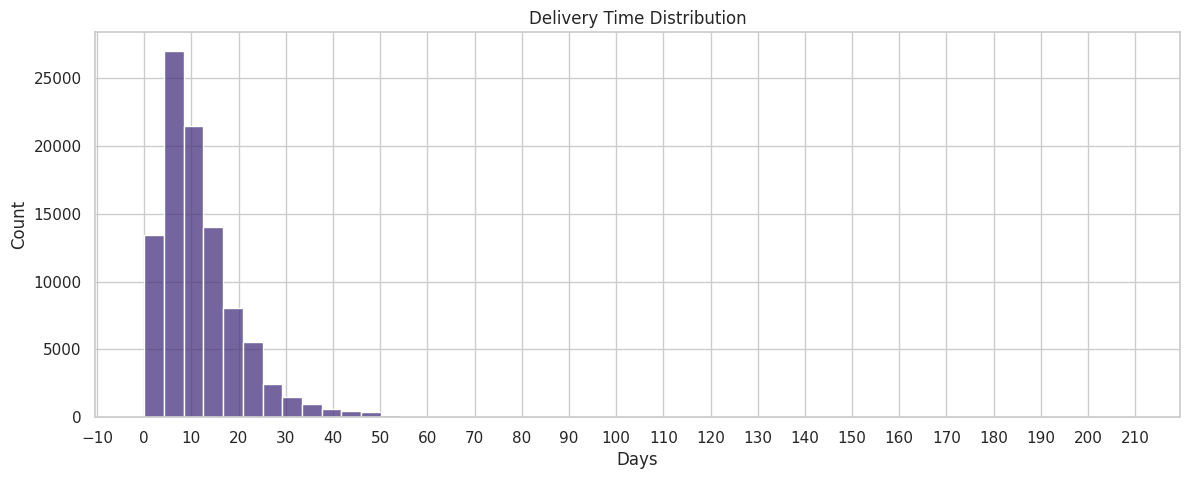

In [ ]:
import matplotlib.ticker as ticker
plt.figure(figsize=(14, 5))
sns.histplot(data=orders_revenue, x='delivery_days', bins=50)
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(10))
plt.title('Delivery Time Distribution')
plt.xlabel('Days')
plt.show()

The middle 50% of orders are delivered within 6 to 15 days (median 10), and the histogram has a long right tail of extreme values. Let's build a boxplot to pinpoint the outliers.

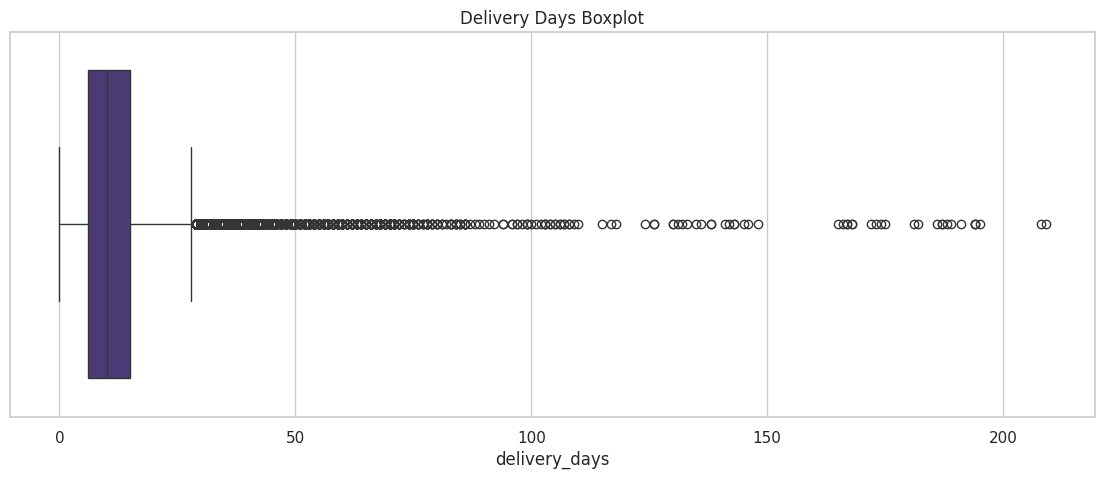

In [ ]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=orders_revenue, x='delivery_days')
plt.title('Delivery Days Boxplot')
plt.show()

The boxplot shows extreme outliers with delivery times of over 100 days. These could be timestamp errors or genuine fulfillment failures. On a marketplace, a delay can come from two places: the seller (slow handover to the carrier) or the carrier (slow transit). The data contains both timestamps, so these cases can be split by stage to see where delays happen. The late delivery rate is 6.77%, which is worth reducing given how strongly late delivery is associated with lower review scores (see Review Analysis).

In [ ]:
Q1 = orders_revenue['delivery_days'].quantile(0.25)
Q3 = orders_revenue['delivery_days'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

delivery_days_outliers = orders_revenue[
    (orders_revenue['delivery_days'] < lower_bound) |
     (orders_revenue['delivery_days'] > upper_bound)
]


print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')

delivery_days_outliers_dropped = orders_revenue[
    (orders_revenue['delivery_days'] > lower_bound) &
    (orders_revenue['delivery_days'] < upper_bound)
]


Q1: 6.0
Q3: 15.0
IQR: 9.0


In [ ]:
average_delivery_time_outliers = delivery_days_outliers['delivery_days'].mean()
average_delivery_time_no_outliers = delivery_days_outliers_dropped['delivery_days'].mean()
delivery_days_outliers_count = len(delivery_days_outliers)

print(f'Number of outliers: {delivery_days_outliers_count}')
print(f'Average Delivery Time for Outliers: {average_delivery_time_outliers:.2f} days')
print(f'Average Delivery Time for Data with no Outliers: {average_delivery_time_no_outliers:.2f} days')

Number of outliers: 5022
Average Delivery Time for Outliers: 40.05 days
Average Delivery Time for Data with no Outliers: 10.56 days


Without outliers, the average delivery time drops to 10.56 days. For the outliers, it is 40.05 days.

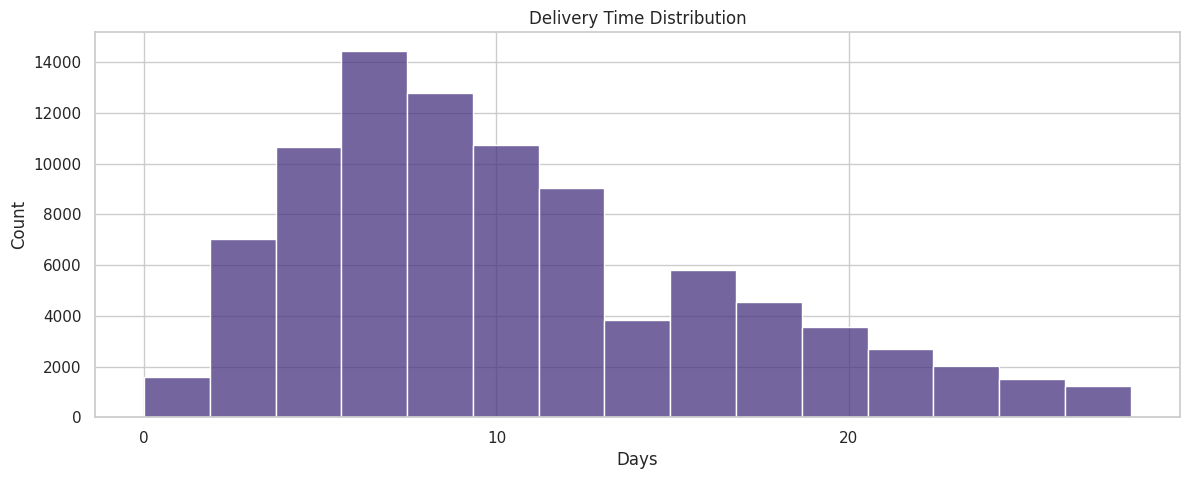

In [ ]:
plt.figure(figsize=(14, 5))
sns.histplot(data=delivery_days_outliers_dropped, x='delivery_days', bins=15)
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(10))
plt.title('Delivery Time Distribution')
plt.xlabel('Days')
plt.show()

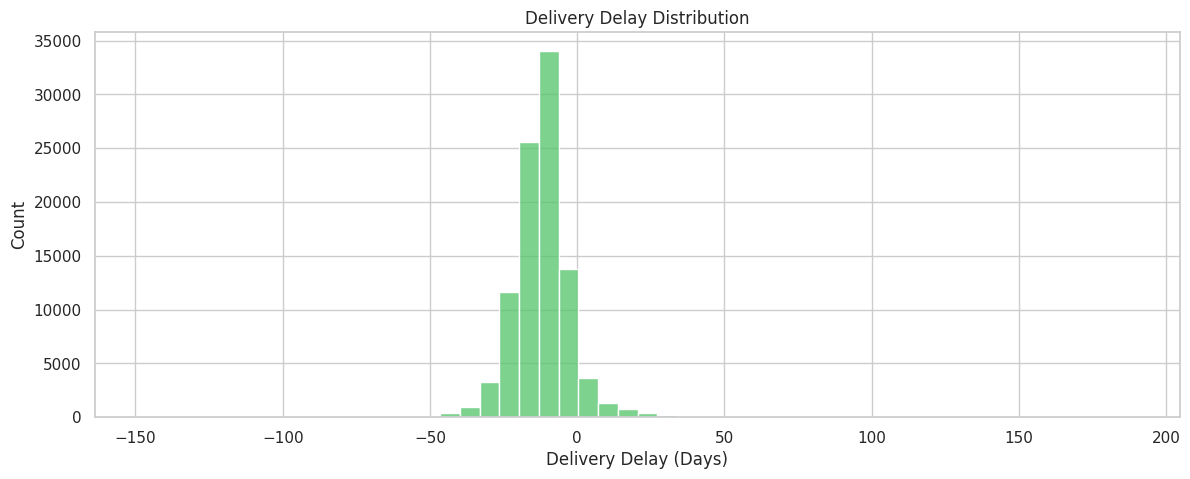

In [ ]:
delivery_delay_days = orders_revenue['delivery_delay'].dt.total_seconds() / (24 * 3600)

plt.figure(figsize=(14, 5))
sns.histplot(x=delivery_delay_days, bins=50, color=viridis_colors[7])
plt.title('Delivery Delay Distribution')
plt.xlabel('Delivery Delay (Days)')
plt.show()

The delivery delay histogram is centered to the left of zero, which means most orders arrive before the estimated delivery date. This matches the 93.22% on-time rate and suggests that the delivery estimates shown to customers are conservative.

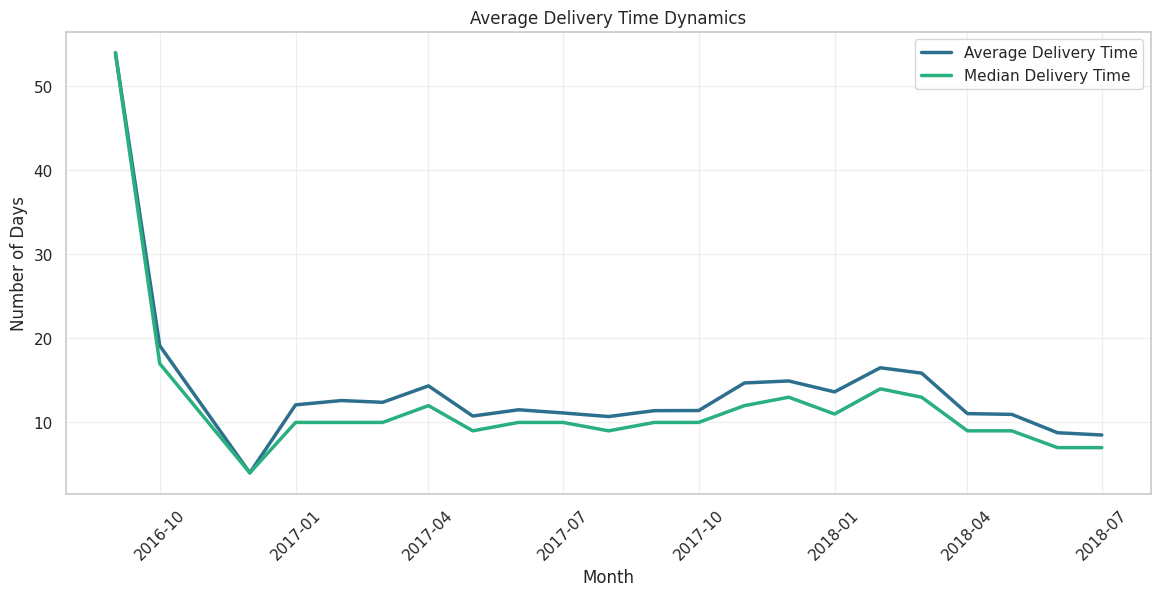

In [ ]:
# monthly delivery time
monthly_delivery = orders_revenue.groupby('order_month').agg(
    avg_delivery_days=('delivery_days', 'mean'),
    median_delivery_days=('delivery_days', 'median')
).reset_index()

last_month = monthly_delivery['order_month'].max()
monthly_delivery = monthly_delivery[monthly_delivery['order_month'] < last_month].copy()

monthly_delivery['order_month'] = monthly_delivery['order_month'].dt.to_timestamp()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_delivery, x='order_month', y='avg_delivery_days', color=viridis_colors[3], linewidth=2.5, label='Average Delivery Time')
sns.lineplot(data=monthly_delivery, x='order_month', y='median_delivery_days', color=viridis_colors[6], linewidth=2.5, label='Median Delivery Time')
plt.title('Average Delivery Time Dynamics')
plt.xlabel('Month')
plt.ylabel('Number of Days')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
orders_revenue[orders_revenue['order_month'] == orders_revenue['order_month'].min()]

,order_id,total_order_value,total_freight,number_of_items,customer_id,order_purchase_timestamp,order_status,delivery_days,shipping_time,approval_time,delivery_delay,customer_unique_id,order_month,order_week
74448,bfbd0f9bdef84302105ad712db648a6c,134.97000,8.49000,3,86dc2ffce2dfff336de2f386a786e574,2016-09-15 12:16:38,delivered,54.00000,53 days 04:55:15,0 days,36 days,830d5b7aaa3b6f1e9ad63703bec97d23,2016-09,2016-09-12/2016-09-18


The Average Delivery Time Dynamics graph shows the average and median monthly values for delivery time metric. It's important to note that the data for this graph is aggregated by the date of order placement, so even if the order is delivered next month, it still adds up to the order month's total.

The monthly average delivery time is noisy and elevated in the first month of data (September 2016). This is a small-sample effect: only one delivered order from that month is in the data (delivered 54 days after purchase, 36 days later than estimated), and December 2016 is also based on a single order. So this value reflects Olist's earliest onboarding activity rather than a real operational signal.

After the noisy start, the line settles down and gradually improves during 2018. This might be related to the growth of the marketplace: more sellers mean wider regional coverage, so more orders are shipped from sellers closer to the customer.

There is a visible increase around November 2017, which lines up with the Black Friday surge, and a second one at the start of 2018, which may be related to the post-holiday logistics load and needs further investigation. Understanding these seasonal peaks helps sellers and logistics partners plan capacity ahead of high-demand periods.

The median line is consistently below the average, which means that each month a group of unusually slow deliveries pulls the average up.

#### **Order Status Analysis**

In [ ]:
unique_statuses = orders_revenue_all_statuses['order_status'].unique()
unique_statuses

array(['delivered', 'unavailable', 'shipped', 'canceled', 'invoiced',
       'processing', 'approved', 'created'], dtype=object)

In [ ]:
total_orders_all_statuses = orders_revenue_all_statuses['order_id'].nunique()

delivery_sucsess_rate = len(orders_revenue_all_statuses[orders_revenue_all_statuses['order_status'] == 'delivered']) / total_orders_all_statuses * 100
cancellation_rate = len(orders_revenue_all_statuses[orders_revenue_all_statuses['order_status'] == 'canceled']) / total_orders_all_statuses * 100
unavailable_rate = len(orders_revenue_all_statuses[orders_revenue_all_statuses['order_status'] == 'unavailable']) / total_orders_all_statuses * 100
processing_rate = len(orders_revenue_all_statuses[orders_revenue_all_statuses['order_status'] == 'processing']) / total_orders_all_statuses * 100

print(f'Delivery Success Rate: {delivery_sucsess_rate:.2f}%')
print(f'Cancellation Rate: {cancellation_rate:.2f}%')
print(f'Unavailable Rate: {unavailable_rate:.2f}%')
print(f'Processing Rate: {processing_rate:.2f}%')

Delivery Success Rate: 97.02%
Cancellation Rate: 0.63%
Unavailable Rate: 0.61%
Processing Rate: 0.30%


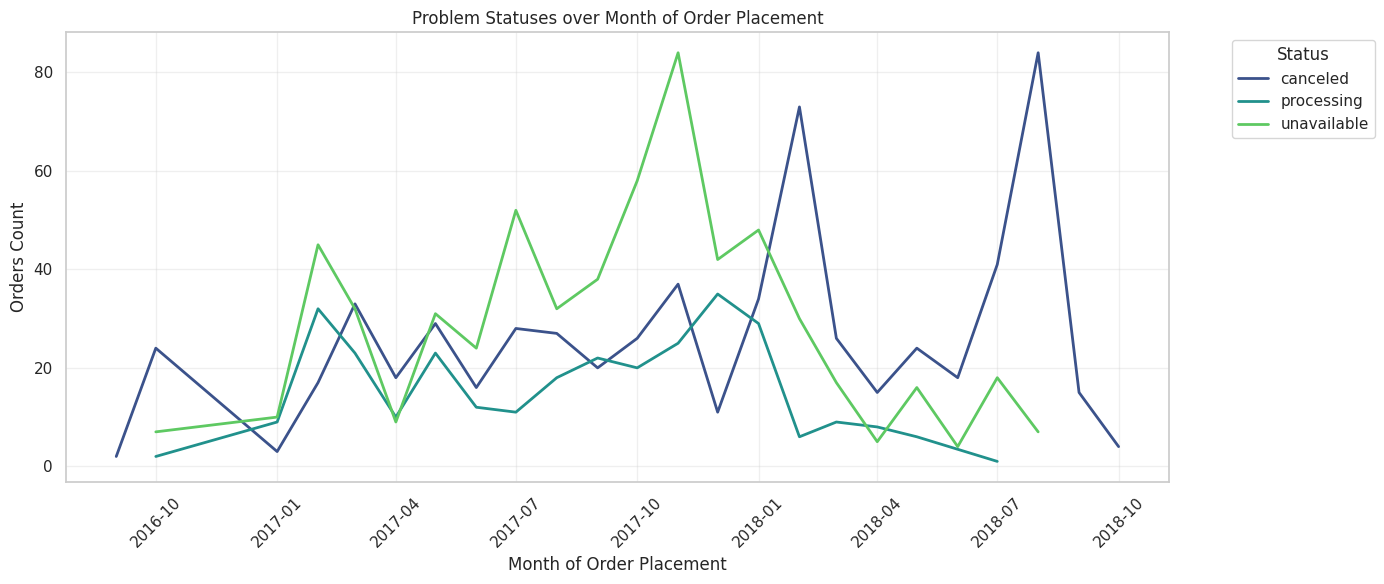

In [ ]:
orders_revenue_all_statuses['order_month'] = orders_revenue_all_statuses['order_purchase_timestamp'].dt.to_period('M')

# aggregation by month and status
status_time = orders_revenue_all_statuses.groupby(['order_month', 'order_status']).size().reset_index(name='orders_count')
status_time['month_for_plot'] = status_time['order_month'].dt.to_timestamp()

# filtering by 'canceled', 'unavailable' and 'processing'
problem_orders = status_time[status_time['order_status'].isin(['canceled', 'unavailable', 'processing'])]

# plotting the line
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=problem_orders,
    x='month_for_plot',
    y='orders_count',
    hue='order_status',
    linewidth=2,
    palette='viridis'
)

plt.title('Problem Statuses over Month of Order Placement')
plt.xlabel('Month of Order Placement')
plt.ylabel('Orders Count')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title='Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

Since we don't have a timestamp for status changes, this graph shows the number of orders with a certain problem status by the month the order was placed. Since the average approval time is only 0 days and 10 hours, it's likely that most orders reach their final status shortly after placement, so we can assume this graph approximately reflects the number of orders that gained a certain status by month as well.

The problem statuses chart is noisy. 'Unavailable' dominates through 2017 and spikes sharply to 84 orders around November 2017, in line with the Black Friday surge. A demand spike is exactly when listed products run out in sellers' stock, so 'unavailable' orders point to sellers' inventory not being kept in sync with their listings. After the peak, 'unavailable' steadily declines through 2018.

'Canceled' stays steady (mostly 10–37 orders per month) through 2017, then forms two sharp spikes in 2018: about 73 orders in February and about 84 in August. These peaks show a new pattern not seen in 2017 and are worth investigating (for example, by seller or by category).

The 'processing' line shows orders placed almost two years before the end of the dataset that still have the 'processing' status. These are most likely orders that sellers never fulfilled, or whose status was never updated. They should be reviewed as a data-quality or seller-compliance issue.

The overall delivery success rate is high (97.02%). The problem statuses ('canceled', 'unavailable' and 'processing') each account for less than 1% of orders.

#### **Revenue Drivers**

Correlation Matrix:
                   total_order_value  number_of_items  total_freight  \
total_order_value            1.00000          0.18000        0.47000   
number_of_items              0.18000          1.00000        0.38000   
total_freight                0.47000          0.38000        1.00000   
delivery_days                0.10000         -0.03000        0.38000   

                   delivery_days  
total_order_value        0.10000  
number_of_items         -0.03000  
total_freight            0.38000  
delivery_days            1.00000  

P-values Matrix:
                   total_order_value  number_of_items  total_freight  \
total_order_value            0.00000          0.00000        0.00000   
number_of_items              0.00000          0.00000        0.00000   
total_freight                0.00000          0.00000        0.00000   
delivery_days                0.00000          0.00000        0.00000   

                   delivery_days  
total_order_value        0.000

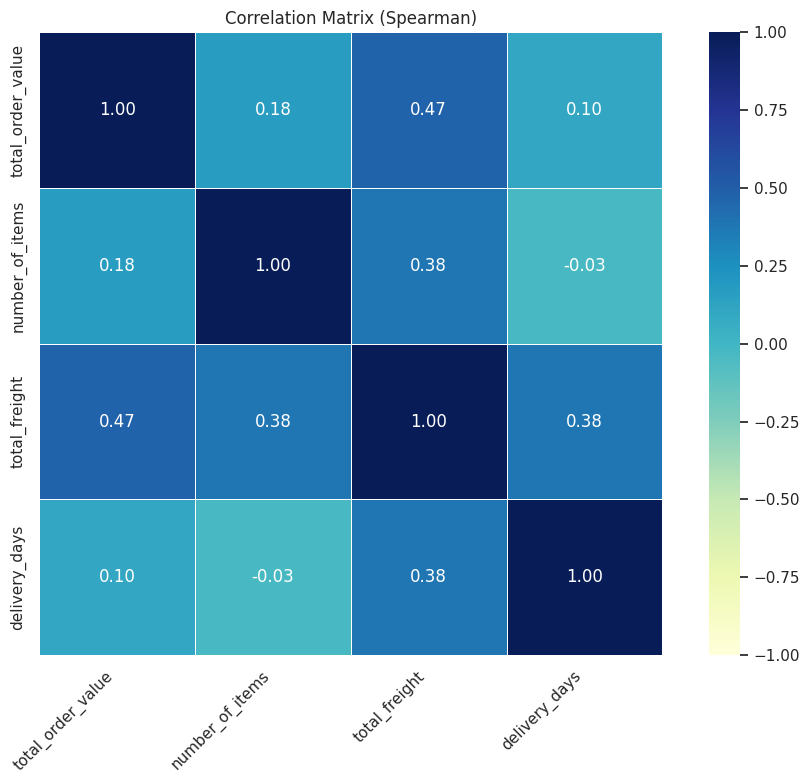

In [ ]:
correlation_metrics = [
    'total_order_value',
    'number_of_items',
    'total_freight',
    'delivery_days'
]

corr_data = orders_revenue[correlation_metrics].dropna()

corr_matrix = corr_data.corr(method='spearman')

p_values = pd.DataFrame(np.zeros_like(corr_matrix), columns=corr_matrix.columns, index=corr_matrix.index)

for i in corr_data.columns:
  for j in corr_data.columns:
    if i == j:
      p_values.loc[i, j] = 0.0
    else:
      _, p_value = stats.spearmanr(corr_data[i], corr_data[j])
      p_values.loc[i, j] = p_value

print('Correlation Matrix:')
print(corr_matrix.round(2))
print('\nP-values Matrix:')
print(p_values.round(4))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', vmin=-1, vmax=1, linewidths=0.5, square=True, cmap="YlGnBu")
plt.title('Correlation Matrix (Spearman)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Most relationships between the metrics are weak (below 0.39). The strongest is between order value and freight (0.47, moderate). Freight is also moderately related to the number of items (0.38) and to delivery time (0.38), which is consistent with freight depending on package size and the distance between seller and customer.

## Customer Analysis
### Business Questions:
Where are most customers located?
What share of customers return to the marketplace?

**KPI:**
- Number of Customers
- Repeat Customers
- Average Number of Orders per Customer
- Total Spent
- Repeat Customer Rate
- Average Customer Lifetime (Last Purchase - First Purchase)

#### **Customer Overview**

In [ ]:
customers_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype          
---  ------                    --------------  -----          
 0   customer_id               99441 non-null  object         
 1   customer_unique_id_x      99441 non-null  object         
 2   customer_zip_code_prefix  99441 non-null  int64          
 3   customer_city             99441 non-null  object         
 4   customer_state            99441 non-null  object         
 5   order_id                  99441 non-null  object         
 6   total_order_value         99441 non-null  float64        
 7   total_freight             99441 non-null  float64        
 8   number_of_items           99441 non-null  int64          
 9   order_purchase_timestamp  99441 non-null  datetime64[ns] 
 10  order_status              99441 non-null  object         
 11  delivery_days             96476 non-null  float64        
 12  ship

In [ ]:
customers_data_delivered = customers_data[customers_data['order_status'] == 'delivered']

customer_agg = customers_data_delivered.groupby('customer_unique_id_x').agg(
    number_of_orders=('order_id', 'nunique'),
    total_revenue=('total_order_value', 'sum'),
    state=('customer_state', 'min')
).reset_index()

customer_agg['is_repeat'] = np.where(customer_agg['number_of_orders'] > 1, 1, 0)

total_customers = customers_data_delivered['customer_unique_id_x'].nunique()
repeat_customer_rate = customer_agg['is_repeat'].sum() / total_customers * 100

average_orders_per_customer = customer_agg['number_of_orders'].mean()
average_revenue_per_customer = customer_agg['total_revenue'].mean()
median_revenue_per_customer = customer_agg['total_revenue'].median()

customer_lifetimes = customers_data_delivered.groupby('customer_unique_id_x').agg(
    first_purchase=('order_purchase_timestamp', 'min'),
    last_purchase=('order_purchase_timestamp', 'max')
)

customer_lifetimes['lifetime_days'] = (customer_lifetimes['last_purchase'] - customer_lifetimes['first_purchase']).dt.days

# average customer lifetime (for all customers): last order time - first order time
average_customer_lifetime = customer_lifetimes['lifetime_days'].mean()

# average customer lifetime (for repeat customers)
repeat_customer_lifetimes = customer_lifetimes[customer_lifetimes['lifetime_days'] > 0]
avg_lifetime_repeat = repeat_customer_lifetimes['lifetime_days'].mean()

print(f'Total Customers: {total_customers}')
print(f'Repeat Customer Rate: {repeat_customer_rate:.2f}%')
print(f'Average Orders per Customer: {average_orders_per_customer:.2f}')
print(f'Average Revenue per Customer: R$ {average_revenue_per_customer:.2f}')
print(f'Median Revenue per Customer: R$ {median_revenue_per_customer:.2f}')
print(f'Average Customer Lifetime (for all customers): {average_customer_lifetime:.2f} days')
print(f'Average Customer Lifetime (for repeat customers): {avg_lifetime_repeat:.2f} days')

Total Customers: 93358
Repeat Customer Rate: 3.00%
Average Orders per Customer: 1.03
Average Revenue per Customer: R$ 141.62
Median Revenue per Customer: R$ 89.73
Average Customer Lifetime (for all customers): 2.63 days
Average Customer Lifetime (for repeat customers): 123.39 days


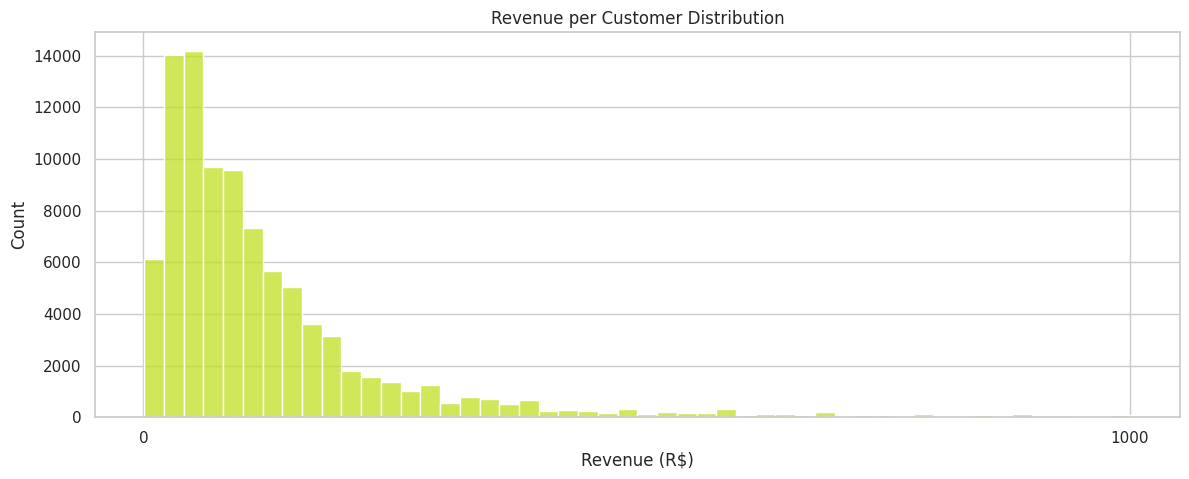

In [ ]:
# filtering out extreme outliers
limit = customer_agg['total_revenue'].quantile(0.99)
histplot_customers_data = customer_agg[customer_agg['total_revenue'] < limit]


plt.figure(figsize=(14, 5))
sns.histplot(x=histplot_customers_data['total_revenue'], bins=50, color=viridis_colors[9])
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(1000))
plt.title('Revenue per Customer Distribution')
plt.xlabel('Revenue (R$)')
plt.show()

In [ ]:
one_time_customers = customer_agg[customer_agg['is_repeat'] == 0]

average_revenue_per_one_time_customer = one_time_customers['total_revenue'].mean()
median_revenue_per_one_time_customer = one_time_customers['total_revenue'].median()
average_revenue_per_repeat_customer = customer_agg[customer_agg['is_repeat'] == 1]['total_revenue'].mean()
median_revenue_per_repeat_customer = customer_agg[customer_agg['is_repeat'] == 1]['total_revenue'].median()

print(f'Average Revenue per One-Time Customer: R$ {average_revenue_per_one_time_customer:.2f}')
print(f'Median Revenue per One-Time Customer: R$ {median_revenue_per_one_time_customer:.2f}')
print(f'Average Revenue per Repeat Customer: R$ {average_revenue_per_repeat_customer:.2f}')
print(f'Median Revenue per Repeat Customer: R$ {median_revenue_per_repeat_customer:.2f}')

Average Revenue per One-Time Customer: R$ 137.96
Median Revenue per One-Time Customer: R$ 86.96
Average Revenue per Repeat Customer: R$ 260.05
Median Revenue per Repeat Customer: R$ 182.10


There are 93,358 unique customers with at least one delivered order, and only 3% of them made more than one purchase. Part of this is expected: the data covers Olist's early growth, and many popular categories (such as bed_bath_table) are not bought often. Still, repeat customers spend about twice as much (median R\$ 182 vs R\$ 87), so retention is valuable. On a marketplace, the most direct levers are the ones that shape the buying experience: delivery speed and reliability, seller quality, and catalog breadth.

Customers place 1.03 orders on average. Because spending per customer is right-skewed, the median (R\$ 89.73) describes a typical customer better than the average (R\$ 141.62). For repeat customers, the average time between the first and last purchase is 123 days.

#### **Geographic Analysis**

In [ ]:
by_state = customer_agg.groupby('state').agg(
    total_revenue=('total_revenue', 'sum'),
    average_revenue_per_customer=('total_revenue', 'mean'),
    median_revenue_per_customer=('total_revenue', 'median'),
    avg_orders_per_customer=('number_of_orders', 'mean'),
    number_of_repeat_customers=('is_repeat', 'sum'),
    number_of_customers=('customer_unique_id_x', 'nunique')
).reset_index()

by_state = by_state.sort_values(by='total_revenue', ascending=False)
by_state['cumulative_revenue'] = by_state['total_revenue'].cumsum()
total_revenue = by_state['total_revenue'].sum()
by_state['cumulative_percentage'] = (by_state['cumulative_revenue'] / total_revenue) * 100
by_state

,state,total_revenue,average_revenue_per_customer,median_revenue_per_customer,avg_orders_per_customer,number_of_repeat_customers,number_of_customers,cumulative_revenue,cumulative_percentage
25,SP,5066284.14000,129.44337,79.90000,1.03436,1213,39139,5066284.14000,38.31853
18,RJ,1759547.33000,147.68737,95.28000,1.03668,391,11914,6825831.47000,51.62676
10,MG,1552873.17000,141.18312,89.99000,1.03273,325,10999,8378704.64000,63.37182
22,RS,728925.47000,141.07325,89.90000,1.03445,158,5167,9107630.11000,68.88501
17,PR,666527.21000,139.76247,87.80000,1.03313,142,4769,9774157.32000,73.92625
23,SC,506737.23000,147.09354,89.99000,1.02903,93,3445,10280894.55000,77.75892
4,BA,493847.55000,156.37984,98.00000,1.03167,90,3158,10774742.10000,81.49411
6,DF,296770.80000,146.98900,89.90000,1.03219,61,2019,11071512.90000,83.73872
8,GO,283184.60000,149.51668,97.85000,1.03432,59,1894,11354697.50000,85.88057
7,ES,268733.35000,139.38452,89.90000,1.03527,57,1928,11623430.85000,87.91312


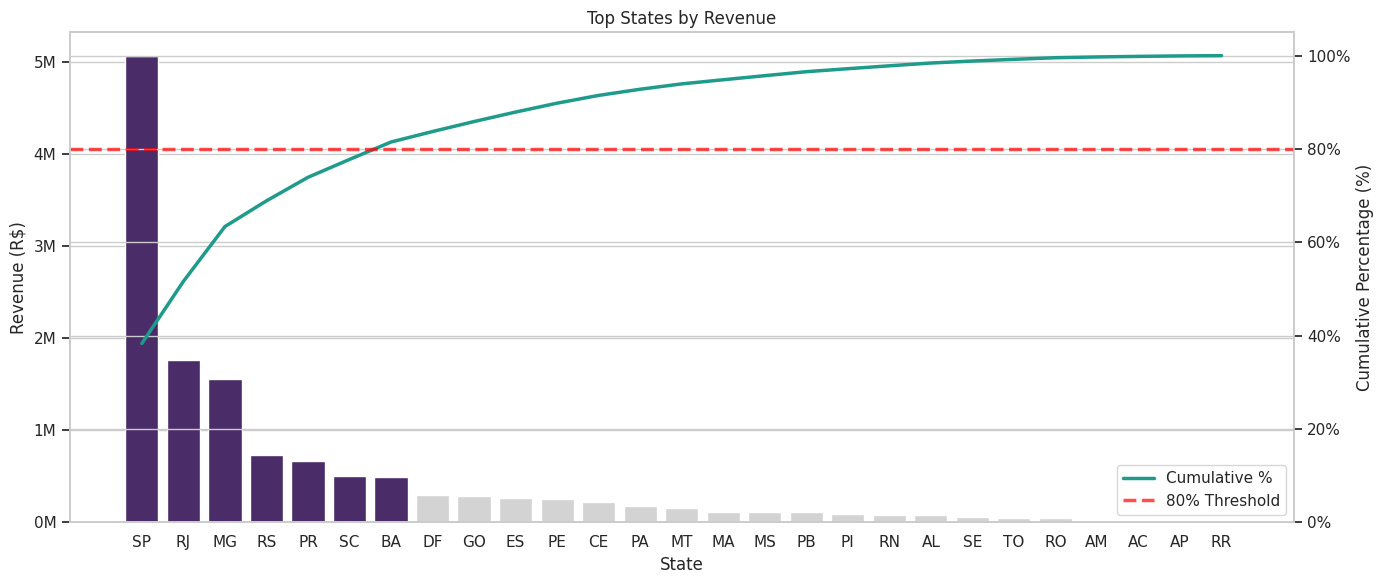

In [ ]:
from matplotlib.ticker import PercentFormatter

# number of top states needed to reach the 80% cumulative threshold (7 in this data)
n_top_states = int((by_state['cumulative_percentage'] < 80).sum()) + 1
highlight_color = viridis_colors[0]
muted_color = '#D3D3D3'

custom_palette = [highlight_color if i < n_top_states else muted_color for i in range(len(by_state))]

fig, ax1 = plt.subplots(figsize=(14, 6))
sns.barplot(data=by_state, x='state', y='total_revenue', ax=ax1, palette=custom_palette, hue='state')
ax1.yaxis.set_major_formatter(FuncFormatter(format_m))
ax1.set_xlabel('State')
ax1.set_ylabel('Revenue (R$)')
ax1.set_title('Top States by Revenue')

ax2 = ax1.twinx()
sns.lineplot(data=by_state, x='state', y='cumulative_percentage', ax=ax2, color=viridis_colors[5], linewidth=2.5, label='Cumulative %')
ax2.yaxis.set_major_formatter(PercentFormatter())
ax2.set_ylabel('Cumulative Percentage (%)')
ax2.set_ylim(0, 105)

ax2.axhline(80, color='red', linestyle='--', alpha=0.7, label='80% Threshold', linewidth=2.5)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

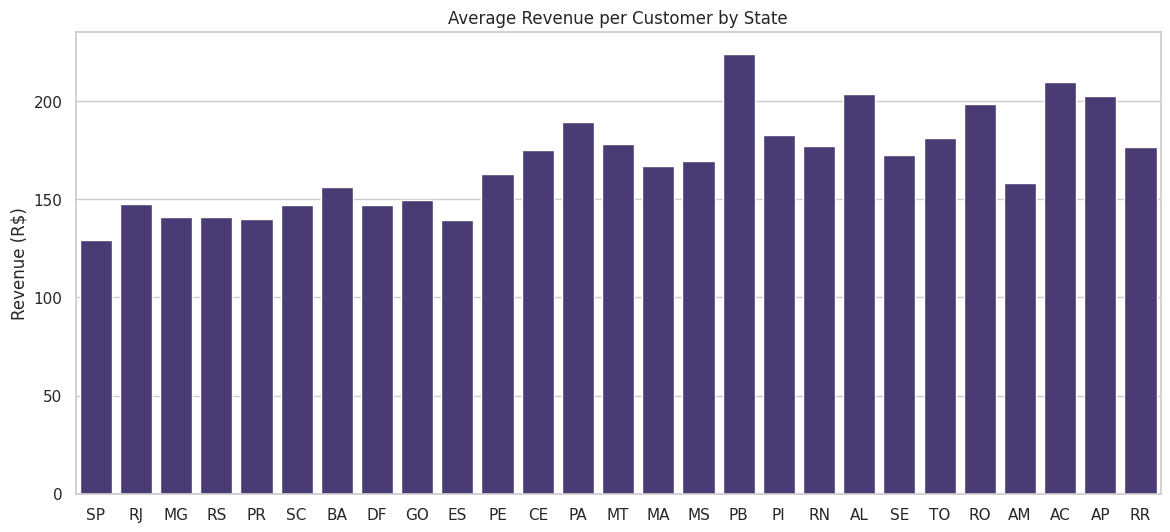

In [ ]:
plt.figure(figsize=(14, 6))
sns.barplot(data=by_state, x='state', y='average_revenue_per_customer')
plt.title('Average Revenue per Customer by State')
plt.xlabel('')
plt.ylabel('Revenue (R$)')
plt.show()

Pareto analysis shows that only 7 states (São Paulo, Rio de Janeiro, Minas Gerais, Rio Grande do Sul, Paraná, Santa Catarina and Bahia) generate 81% of total GMV, and São Paulo alone generates about 38%. The Average Revenue per Customer by State chart shows that the leading states do not stand out by revenue per customer: it is lowest in São Paulo (R\$ 129), while Rio de Janeiro and Santa Catarina are slightly above the national average (R\$ 142). Some smaller, more remote states show higher averages, but these are based on far fewer customers, so they should be interpreted with caution.

One possible explanation for the higher averages in remote states is distance: customers there face higher freight and longer deliveries, so they may order less often and choose more expensive items, for which shipping is worth it. Comparing customer and seller locations (seller_state) and the number of customers per state would help to check this.

## Product and Seller Analysis
### Business Questions:
Which categories generate the most revenue?
How is revenue distributed among sellers?

**KPI:**
- Top Categories by Revenue and by Orders
- Most Expensive Categories
- Average Product Price per Category
- Average Freight per Category
- Average Revenue per Seller
- Average Orders per Seller
- Average Products per Seller

#### **Product Category Performance**

In [ ]:
orders_delivered = orders_revenue[orders_revenue['order_status'] == 'delivered']['order_id']
products_delivered = product_data[product_data['order_id'].isin(orders_delivered)]

category_agg = products_delivered.groupby('product_category_name_english').agg(
    total_revenue=('price', 'sum'),
    number_of_orders=('order_id', 'nunique'),
    average_product_price=('price', 'mean'),
    average_freight_per_category=('freight_value', 'mean')
).reset_index()

category_agg = category_agg.sort_values(by='total_revenue', ascending=False)
category_agg

,product_category_name_english,total_revenue,number_of_orders,average_product_price,average_freight_per_category
43,health_beauty,1233131.72000,8647,130.28333,18.90732
73,watches_gifts,1166176.98000,5495,199.04028,16.75305
7,bed_bath_table,1023434.76000,9272,93.43876,18.42185
67,sports_leisure,954852.55000,7530,113.25496,19.38137
15,computers_accessories,888724.61000,6530,116.26434,18.83819
...,...,...,...,...,...
35,flowers,1110.04000,29,33.63758,14.81424
46,home_comfort_2,760.27000,24,25.34233,13.67700
11,cds_dvds_musicals,730.00000,12,52.14286,16.07071
29,fashion_childrens_clothes,519.95000,7,74.27857,11.24571


In [ ]:
category_agg.describe()

,total_revenue,number_of_orders,average_product_price,average_freight_per_category
count,74.00000,74.00000,74.00000,74.00000
mean,178668.89338,1314.54054,146.07140,21.54080
std,291294.38060,2189.54000,145.83653,8.11148
min,283.29000,2.00000,25.34233,11.24571
25%,7830.76750,73.75000,79.04755,16.37865
50%,45417.06500,241.50000,114.75965,19.39810
75%,183925.33500,1357.50000,152.50171,22.53909
max,1233131.72000,9272.00000,1098.91528,48.57095


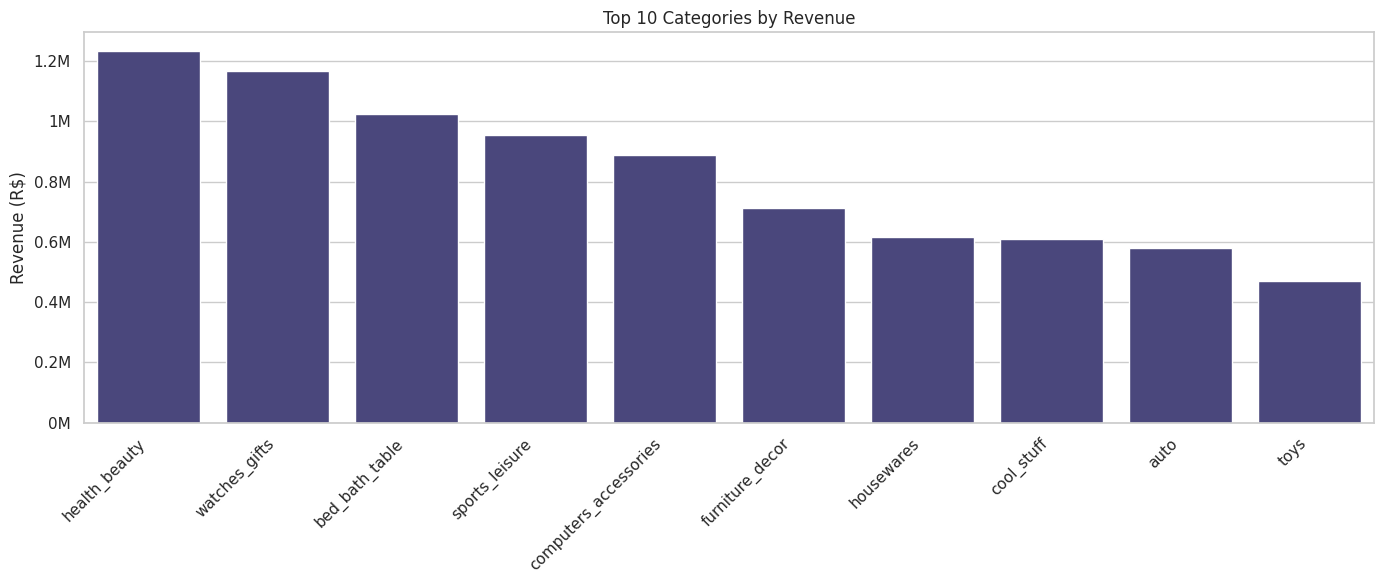

In [ ]:
top10_by_revenue = category_agg.head(10)
plt.figure(figsize=(14, 6))
sns.barplot(data=top10_by_revenue, x='product_category_name_english', y='total_revenue', color=viridis_colors[1])
plt.gca().yaxis.set_major_formatter(FuncFormatter(format_m))
plt.title('Top 10 Categories by Revenue')
plt.xlabel('')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

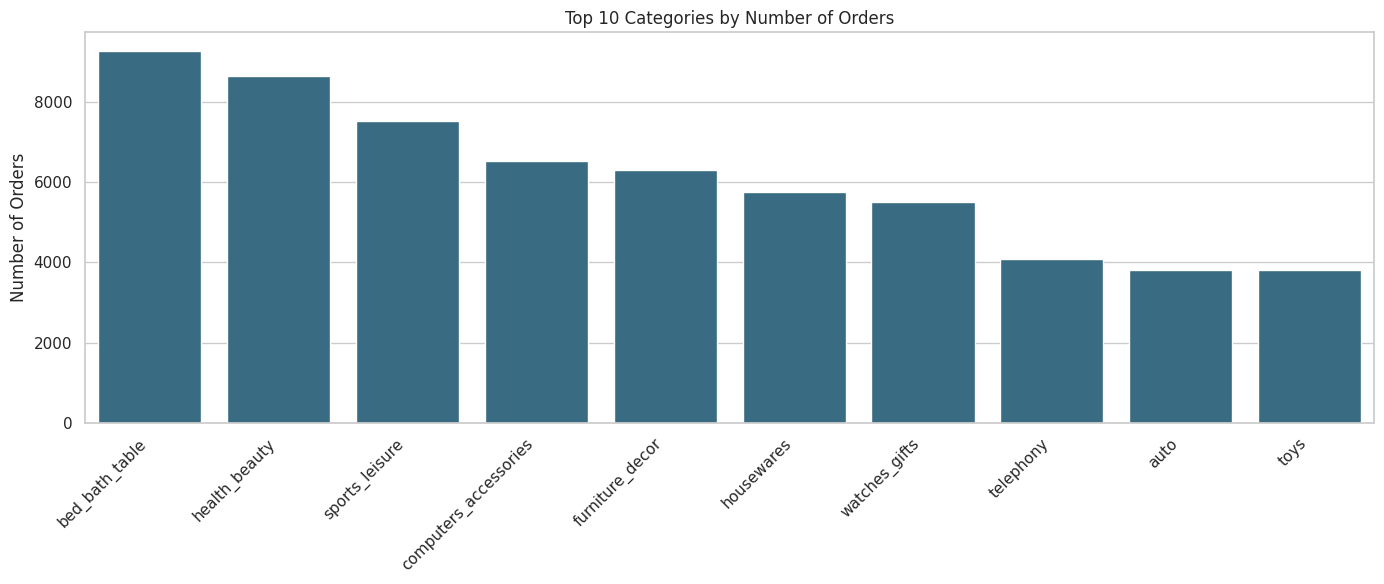

In [ ]:
top10_by_number_of_orders = category_agg.sort_values(by='number_of_orders', ascending=False).copy()
top10_by_number_of_orders = top10_by_number_of_orders.head(10)
plt.figure(figsize=(14, 6))
sns.barplot(data=top10_by_number_of_orders, x='product_category_name_english', y='number_of_orders', color=viridis_colors[3])
plt.title('Top 10 Categories by Number of Orders')
plt.xlabel('')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

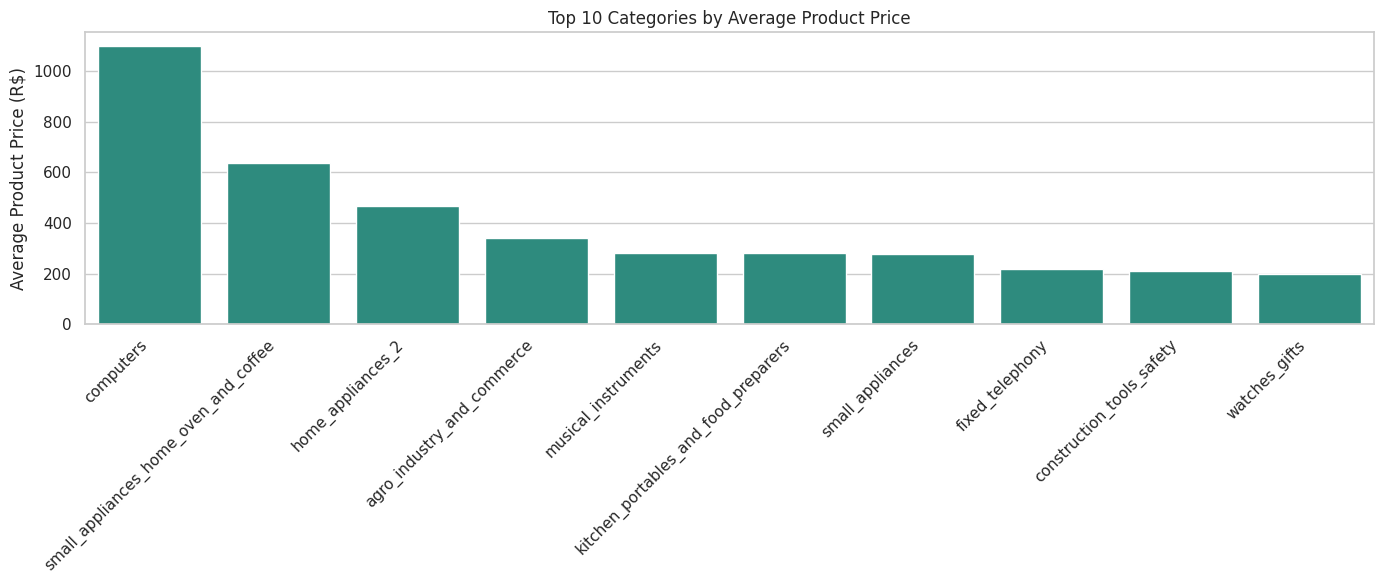

In [ ]:
top10_by_avg_product_price = category_agg.sort_values(by='average_product_price', ascending=False).copy()
top10_by_avg_product_price = top10_by_avg_product_price.head(10)
plt.figure(figsize=(14, 6))
sns.barplot(data=top10_by_avg_product_price, x='product_category_name_english', y='average_product_price', color=viridis_colors[5])
plt.title('Top 10 Categories by Average Product Price')
plt.xlabel('')
plt.ylabel('Average Product Price (R$)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
category_agg[category_agg['product_category_name_english'].isin(top10_by_avg_product_price['product_category_name_english'])]

,product_category_name_english,total_revenue,number_of_orders,average_product_price,average_freight_per_category
73,watches_gifts,1166176.98000,5495,199.04028,16.75305
14,computers,218684.14000,177,1098.91528,48.57095
57,musical_instruments,184315.74000,611,283.12710,27.45220
65,small_appliances,182754.12000,609,277.74182,23.33488
45,home_appliances_2,107953.95000,227,467.33312,44.39208
0,agro_industry_and_commerce,70566.10000,177,342.55388,27.36505
34,fixed_telephony,55315.21000,212,216.92239,17.65227
66,small_appliances_home_oven_and_coffee,46589.56000,72,638.21315,36.38822
19,construction_tools_safety,38773.22000,159,211.87552,20.38689
52,kitchen_portables_and_food_preparers,3933.63000,13,280.97357,21.03000


Sales on the platform are driven by volume rather than by expensive products: most categories in the top 10 by revenue are also in the top 10 by number of orders, with health_beauty and bed_bath_table leading both. watches_gifts stands out: it is second by revenue and also in the top 10 by average price, so it combines strong demand with high item value. Categories like this are good candidates for attracting more sellers and promoting their listings.

#### **Seller Performance**

In [ ]:
seller_agg = products_delivered.groupby('seller_id').agg(
    total_revenue=('price', 'sum'),
    orders_per_seller=('order_id', 'nunique'),
    products_per_seller=('product_id', 'nunique')
)

avg_revenue_per_seller = seller_agg['total_revenue'].mean()
median_revenue_per_seller = seller_agg['total_revenue'].median()
avg_orders_per_seller = seller_agg['orders_per_seller'].mean()
median_orders_per_seller = seller_agg['orders_per_seller'].median()
avg_products_per_seller = seller_agg['products_per_seller'].mean()
median_products_per_seller = seller_agg['products_per_seller'].median()

print(f'Average Revenue per Seller: R$ {avg_revenue_per_seller:.2f}')
print(f'Median Revenue per Seller: R$ {median_revenue_per_seller:.2f}')
print(f'Average Orders per Seller: {avg_orders_per_seller:.2f} orders')
print(f'Median Orders per Seller: {median_orders_per_seller:.2f} orders')
print(f'Average Products per Seller: {avg_products_per_seller:.2f} products')
print(f'Median Products per Seller: {median_products_per_seller:.2f} products')

Average Revenue per Seller: R$ 4451.68
Median Revenue per Seller: R$ 846.17
Average Orders per Seller: 32.94 orders
Median Orders per Seller: 7.00 orders
Average Products per Seller: 11.33 products
Median Products per Seller: 4.00 products


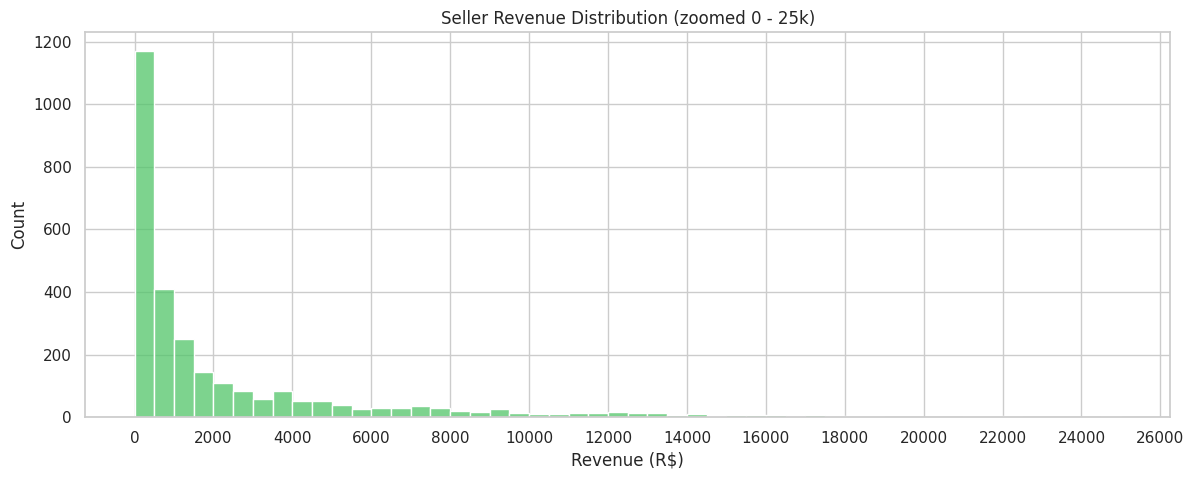

In [ ]:
plt.figure(figsize=(14, 5))
sns.histplot(x=seller_agg['total_revenue'], bins=50, binrange=(0, 25000), color=viridis_colors[7])
plt.title('Seller Revenue Distribution (zoomed 0 - 25k)')
plt.xlabel('Revenue (R$)')
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(2000))
plt.show()

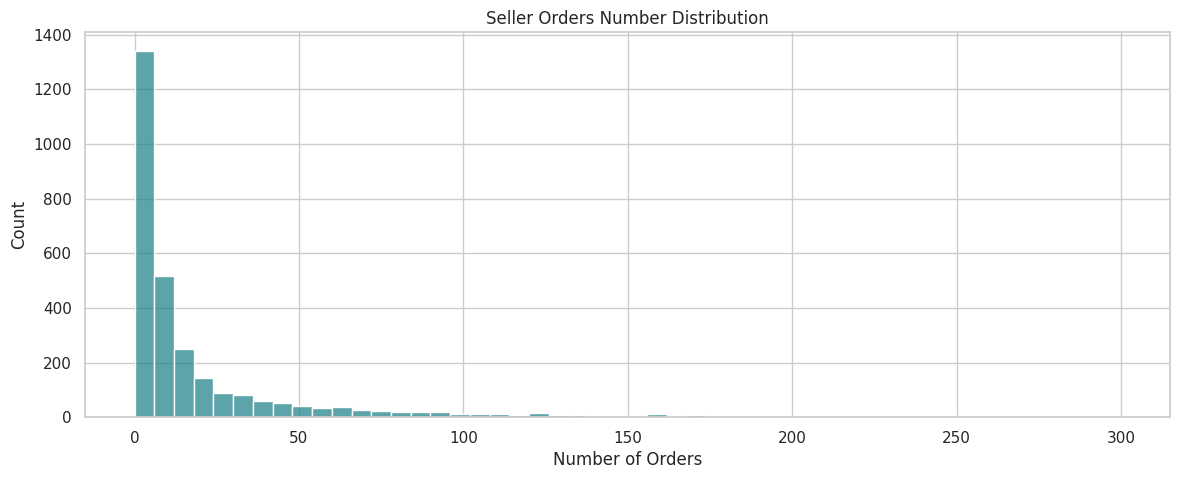

In [ ]:
plt.figure(figsize=(14, 5))
sns.histplot(x=seller_agg['orders_per_seller'], bins=50, binrange=(0, 300), color=viridis_colors[4])
plt.title('Seller Orders Number Distribution')
plt.xlabel('Number of Orders')
plt.show()

Seller metrics are highly right-skewed. The average seller generates R\$ 4,452 in sales, but the median seller only R\$ 846. Sellers complete about 33 orders on average versus a median of 7, and list 11 products on average versus a median of 4. This points to a typical marketplace long tail: a small group of large sellers probably generates a large share of sales (the exact share was not measured), while most sellers are small. If so, Olist depends on keeping its top sellers, and there is room to help small sellers grow.

## Payment Analysis
### Business Questions:
Which payment types are the most popular?
Are more expensive purchases paid in installments more often?

**KPI:**
- Payment Type
- Installments Distribution
- Order Value vs Installments
- Revenue by Payment Type
- Installment Usage Rate

#### **Payment Preferences**

In [ ]:
order_payments['payment_type'].unique()

array(['credit_card', 'boleto', 'voucher', 'debit_card', 'not_defined'],
      dtype=object)

- **Credit Card:** the most common payment method on the platform. In the Brazilian market, it often allows customers to split the purchase amount into monthly installments.

- **Boleto:** a popular Brazilian cash payment method (Boleto Bancário). It generates a barcode ticket that customers can pay at banks, ATMs, or via online banking. Processing usually takes a few business days.

- **Voucher:** payment made with store credit, a gift card, or a promotional coupon.

- **Debit Card:** a direct and instant electronic payment deducted from the customer's bank account.

- **Not Defined:** missing payment information. This usually occurs when an order is canceled or abandoned by the customer before checkout is completed.

In [ ]:
payments_delivered = order_payments[order_payments['order_id'].isin(orders_delivered)]

payments_delivered = payments_delivered.merge(
    orders_revenue[[
        'order_id',
        'total_order_value',
        'total_freight'
    ]],
    on='order_id',
    how='left'
)

In [ ]:

payment_types = payments_delivered.groupby('payment_type').agg(
    total_revenue=('payment_value', 'sum'),
    orders_count=('order_id', 'nunique'),
    average_order_value=('total_order_value', 'mean'),
    median_order_value=('total_order_value', 'median')
).reset_index().sort_values(by='total_revenue', ascending=False)
total_orders = payments_delivered['order_id'].nunique()
payment_types['payment_type_distribution_percent'] = payment_types['orders_count'] / total_orders * 100
payment_types['revenue_distribution_percent'] = (payment_types['total_revenue'] / payment_types['total_revenue'].sum()) * 100
payment_types

,payment_type,total_revenue,orders_count,average_order_value,median_order_value,payment_type_distribution_percent,revenue_distribution_percent
1,credit_card,12101094.88000,74304,143.10066,89.90000,77.01732,78.46409
0,boleto,2769932.58000,19191,121.40105,74.90000,19.89179,17.96038
3,voucher,343013.19000,3679,115.18643,69.90000,3.81334,2.22411
2,debit_card,208421.12000,1485,119.78220,70.45000,1.53923,1.35141


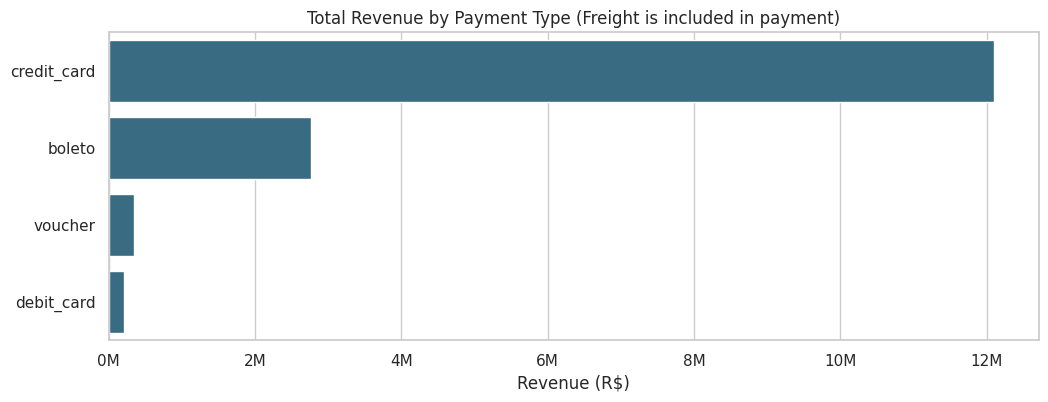

In [ ]:
plt.figure(figsize=(12, 4))
sns.barplot(data=payment_types, x='total_revenue', y='payment_type', color=viridis_colors[3])
plt.title('Total Revenue by Payment Type (Freight is included in payment)')
plt.xlabel('Revenue (R$)')
plt.ylabel('')
plt.gca().xaxis.set_major_formatter(FuncFormatter(format_m))
plt.show()

Credit card is the most popular payment type: it was used in 74,304 orders and accounts for the largest share of payments (over R\$ 12M). Boleto is second (19,191 orders, about R\$ 2.77M), followed by voucher (3,679 orders, over R\$ 300K) and debit card (1,485 orders, over R\$ 200K).

Overall, 77% of orders include a credit card payment, almost 20% include boleto, 3.81% include vouchers, and 1.5% include debit card (the categories are not exclusive: one order can be paid with several payment types).

Average and median order values show that credit card orders tend to be larger than orders paid by other methods. Voucher orders have the lowest average order value, possibly because vouchers are mostly used for smaller purchases.

Note: payment totals are based on payment_value, which includes freight, so they add up to more than the GMV (R\$ 13.22M, item prices only) calculated in the Sales Analysis.

#### **Installment Analysis**

In [ ]:
payments_delivered['payment_installments'].unique()

array([ 8,  1,  2,  3,  6,  5,  4, 10,  7, 12,  9, 13, 15, 24, 11, 18, 14,
       20, 21, 17, 22, 16, 23])

In [ ]:
order_level = payments_delivered.groupby('order_id').agg(
    total_order_value=('total_order_value', 'min'),
    payment_installments=('payment_installments', 'max')
).reset_index()

In [ ]:
orders_with_installments = order_level[order_level['payment_installments'] > 1 ]
total_orders_with_installments = orders_with_installments['order_id'].nunique()


installment_usage_rate = total_orders_with_installments / total_orders * 100
average_number_of_installments = orders_with_installments['payment_installments'].mean()

print(f'Installment Usage Rate: {installment_usage_rate:.2f}%')
print(f'Average Number of Installments: {average_number_of_installments:.2f}')

Installment Usage Rate: 51.47%
Average Number of Installments: 4.75


In [ ]:
orders_1_installment = order_level[order_level['payment_installments'] == 1 ]
one_installment_order_agg = orders_1_installment.groupby('order_id').agg(
    order_value=('total_order_value', 'min')
)

average_order_value_installments = orders_with_installments['total_order_value'].mean()
median_order_value_installments = orders_with_installments['total_order_value'].median()

average_order_value_1_installment = one_installment_order_agg['order_value'].mean()
median_order_value_1_installment = one_installment_order_agg['order_value'].median()

print(f'Average Order Value (with installments): R$ {average_order_value_installments:.2f}')
print(f'Median Order Value (with installments): R$ {median_order_value_installments:.2f}')
print(f'Average Order Value (no installments): R$ {average_order_value_1_installment:.2f}')
print(f'Median Order Value (no installments): R$ {median_order_value_1_installment:.2f}')

Average Order Value (with installments): R$ 172.02
Median Order Value (with installments): R$ 110.00
Average Order Value (no installments): R$ 99.94
Median Order Value (no installments): R$ 59.99


In [ ]:
total_revenue_installments = orders_with_installments['total_order_value'].sum()
total_revenue_no_installments = one_installment_order_agg['order_value'].sum()

print(f'Total Revenue (with installments): R$ {total_revenue_installments:.2f}')
print(f'Total Revenue (no installments): R$ {total_revenue_no_installments:.2f}')

Total Revenue (with installments): R$ 8542651.90
Total Revenue (no installments): R$ 4678711.24


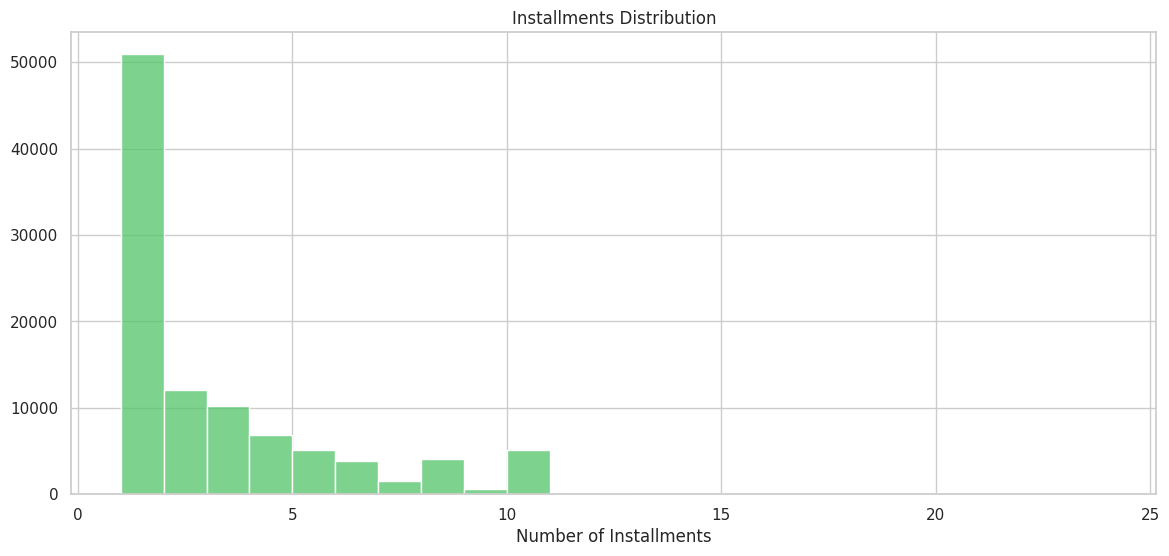

In [ ]:
plt.figure(figsize=(14, 6))
sns.histplot(data=payments_delivered, x='payment_installments', bins=23, color=viridis_colors[7])
plt.title('Installments Distribution')
plt.xlabel('Number of Installments')
plt.ylabel('')
plt.show()

Just over half of orders (51.47%) are paid in installments. Orders paid in installments have a higher average order value (R\$ 172 vs R\$ 100), so they generated R\$ 8.54M of GMV, which is R\$ 3.86M more than orders without installments (R\$ 4.68M).

The installments distribution shows that customers usually split payments into 10 or fewer installments.

#### **Purchase Value vs Installments**

In [ ]:
installment_agg = orders_with_installments.groupby('payment_installments').agg(
    average_order_value=('total_order_value', 'mean'),
    median_order_value=('total_order_value', 'median')
).reset_index().sort_values(by='median_order_value', ascending=False)

installment_agg

,payment_installments,average_order_value,median_order_value
21,24,553.97556,553.38000
17,20,584.50375,402.94500
16,18,455.84704,339.44000
13,15,392.20889,223.17500
20,23,216.00000,216.00000
19,22,209.99000,209.99000
8,10,375.44257,205.00000
18,21,184.93333,189.90000
6,8,279.03242,189.00000
10,12,285.59172,162.99000


In [ ]:
order_level_data = orders_with_installments.groupby('order_id').agg(
    order_total_value=('total_order_value', 'max'),
    max_installments=('payment_installments', 'max')
)

correlation, p_value = stats.spearmanr(
    order_level_data['order_total_value'], order_level_data['max_installments']
)

print(f"Spearman Correlation Coefficient: {correlation:.4f}")
print(f"P-value: {p_value}")


Spearman Correlation Coefficient: 0.3538
P-value: 0.0


The Spearman correlation coefficient of 0.35 indicates a weak-to-moderate positive relationship between order value and the number of installments. In general, median order values are higher for orders with more installments.

## Review Analysis
### Business Question:
Is the review score related to delivery speed and delays?

**KPI:**
- Average Review Score
- Review Score Distribution
- Review Score by Delivery Time
- Review Score by Delay
- Five-Star Rate
- Low-Star Rate

#### **Review Overview**

In [ ]:
order_reviews = order_reviews[order_reviews['order_id'].isin(orders_delivered)]
reviewed_orders = order_reviews['order_id'].nunique()
review_coverage = reviewed_orders / total_delivered_orders * 100

average_review_score = order_reviews['review_score'].mean()
five_star_rate = len(order_reviews[order_reviews['review_score'] == 5]) / len(order_reviews) * 100
low_star_rate = len(order_reviews[order_reviews['review_score'].isin([1, 2])]) / len(order_reviews) * 100

print(f'Average Review Score: {average_review_score:.2f}')
print(f'Five-Star Rate: {five_star_rate:.2f}%')
print(f'Low-Star Rate: {low_star_rate:.2f}%')
print(f'Review Coverage: {review_coverage:.2f}%')

Average Review Score: 4.16
Five-Star Rate: 59.22%
Low-Star Rate: 12.81%
Review Coverage: 99.33%


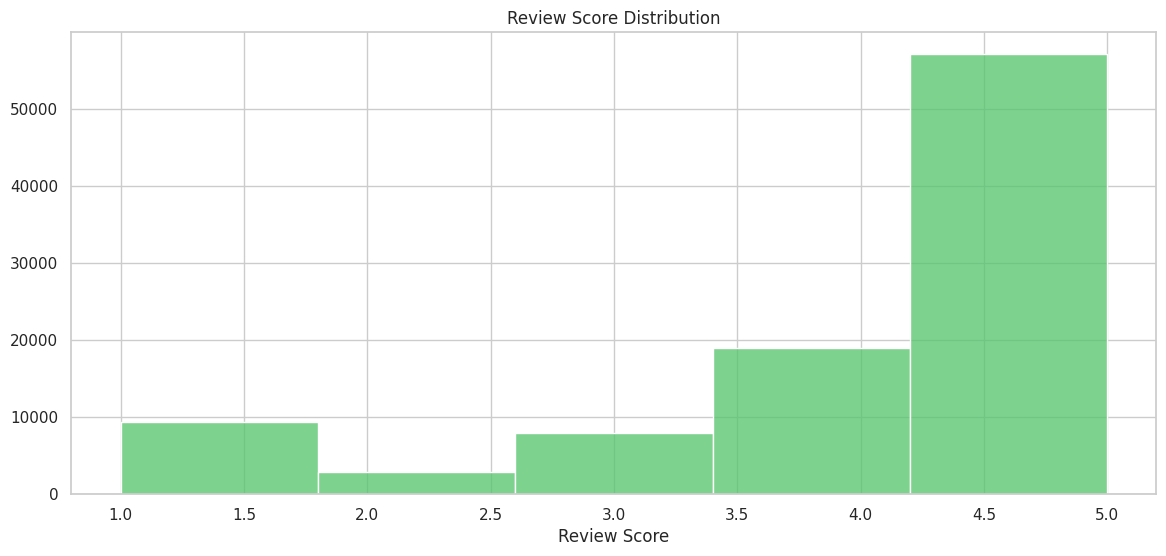

In [ ]:
plt.figure(figsize=(14, 6))
sns.histplot(data=order_reviews, x='review_score', bins=5, color=viridis_colors[7])
plt.title('Review Score Distribution')
plt.xlabel('Review Score')
plt.ylabel('')
plt.show()

#### **Delivery Impact on Reviews**

In [ ]:
orders_review = order_reviews.merge(orders_revenue[[
    'order_id',
    'delivery_days',
    'delivery_delay'
]],
on='order_id',
how='left')



In [ ]:
bins_time = [-1, 5, 10, 15, 20, np.inf]
labels_time = ['0-5 days', '6-10 days', '11-15 days', '16-20 days', '21+ days']

orders_review['delivery_time_group'] = pd.cut(orders_review['delivery_days'], bins=bins_time, labels=labels_time)

avg_score_by_time = orders_review.groupby('delivery_time_group', observed=False).agg(
    average_review_score=('review_score', 'mean'),
    low_rating_share=('review_score', lambda x: (x <= 2).mean() * 100),
    total_orders=('order_id', 'count')
).reset_index()

avg_score_by_time['average_review_score'] = avg_score_by_time['average_review_score'].round(2)
avg_score_by_time['low_rating_share'] = avg_score_by_time['low_rating_share'].round(1)

avg_score_by_time

,delivery_time_group,average_review_score,low_rating_share,total_orders
0,0-5 days,4.43000,7.30000,19229
1,6-10 days,4.35000,8.50000,32850
2,11-15 days,4.25000,9.80000,21166
3,16-20 days,4.09000,12.60000,10719
4,21+ days,3.12000,38.20000,12389


In [ ]:
bins_delay = [-np.inf, -1, 0, 5, 10, np.inf]
labels_delay = ['Delivered Earlier', 'At Time delivery', '1-5 days delay', '6-10 days delay', '11+ days delay']

orders_review['delivery_delay'] = orders_review['delivery_delay'].dt.days

orders_review['delay_group'] = pd.cut(orders_review['delivery_delay'], bins=bins_delay, labels=labels_delay)

avg_score_by_delay = orders_review.groupby('delay_group', observed=False).agg(
    average_review_score=('review_score', 'mean'),
    low_rating_share=('review_score', lambda x: (x <= 2).mean() * 100),
    total_orders=('order_id', 'count')
).reset_index()

avg_score_by_delay['average_review_score'] = avg_score_by_delay['average_review_score'].round(2)
avg_score_by_delay['low_rating_share'] = avg_score_by_delay['low_rating_share'].round(1)

avg_score_by_delay

,delay_group,average_review_score,low_rating_share,total_orders
0,Delivered Earlier,4.29000,9.20000,88653
1,At Time delivery,4.03000,12.40000,1291
2,1-5 days delay,2.99000,41.20000,2729
3,6-10 days delay,1.77000,77.30000,1642
4,11+ days delay,1.71000,78.80000,2038


In [ ]:
clean_data = orders_review[['delivery_days', 'delivery_delay', 'review_score']].dropna()

In [ ]:
groups = [g['review_score'].values for _, g in orders_review.groupby('delivery_time_group', observed=False)]
deliv_time_stat, deliv_time_p = stats.kruskal(*groups)

print(f'Kruskal-Wallis H test stat: {deliv_time_stat}')
print(f'P-value: {deliv_time_p:.6f}')


groups = [g['review_score'].values for _, g in orders_review.groupby('delay_group', observed=False)]
delay_stat, delay_p = stats.kruskal(*groups)

print(f'Kruskal-Wallis H test stat: {delay_stat}')
print(f'P-value: {delay_p:.6f}')

Kruskal-Wallis H test stat: 7543.2854683667365
P-value: 0.000000
Kruskal-Wallis H test stat: 10088.476164295753
P-value: 0.000000


In [ ]:
df = orders_review.dropna(subset=['delivery_time_group', 'delivery_delay']).copy()
df['late'] = df['delivery_delay'] > 0
df['low'] = df['review_score'] <= 2

print((df.pivot_table(index='delivery_time_group', columns='late', values='low', aggfunc='mean', observed=False) * 100).round(1))
print(df.pivot_table(index='delivery_time_group', columns='late', values='low', aggfunc='count', observed=False))

late                   False    True 
delivery_time_group                  
0-5 days             7.30000  6.50000
6-10 days            8.40000 27.10000
11-15 days           9.40000 39.30000
16-20 days          11.40000 43.40000
21+ days            15.50000 66.50000
late                 False  True 
delivery_time_group              
0-5 days             19198     31
6-10 days            32662    188
11-15 days           20891    275
16-20 days           10316    403
21+ days              6877   5512


Orders delivered within 5 days have an average score of 4.43, while orders taking 21+ days average 3.12. Missed delivery dates appear to matter even more: orders that arrive early average 4.29, orders 1–5 days late average 2.99, and orders more than 5 days late average about 1.7. Also, the low rating share grows more drastically for delay groups than for delivery time groups.

A Kruskal-Wallis H test was used to confirm whether review score distributions differ significantly across delivery-time groups (same for the delay groups), since review scores are not normally distributed. The test returned p < 0.05 for both cases, indicating a statistically significant difference in review scores across delivery-time groups and across delay groups. This supports the earlier observation that longer delivery times / delays are associated with lower customer satisfaction.

Customers seem to react less to how long delivery takes and more to whether the promised date is met, although the two overlap (late orders are usually the slow ones). For a marketplace, this suggests that delivery reliability (seller handover time and carrier performance) is an important lever for customer satisfaction.

## Conclusion

### Marketplace Performance

This analysis covered 96,478 delivered orders between September 2016 and August 2018 (713 days). Total GMV from delivered orders (freight excluded): R\$ 13.22M across 93,358 unique customers.

Monthly GMV grew from about R\$ 40K in October 2016 to the R\$ 0.86-0.98M range by mid-2018, more than 20x growth in under two years. However, growth flattened through 2018: monthly GMV has oscillated between R\$ 0.86M and R\$ 0.98M since March 2018 (excluding the incomplete last month) without a clear upward trend, while the November 2017 peak (R\$ 988K) remains the strongest single month. The platform appears to have moved out of its hypergrowth phase into a steady state.    

The typical order is single-item (about 90% of orders contain only one item): median items per order is 1. The middle 50% of orders are worth between R\$ 46 and R\$ 150. Median order value R\$ 86.57 (average R\$ 137.04). Freight adds a further R\$ 22.79 per order on average.

### Customers

The marketplace is almost entirely acquisition driven: only 3.0% of customers made more than one purchase.

Demand is geographically concentrated: seven states (SP, RJ, MG, RS, PR, SC, BA) generate 81% of GMV, with São Paulo alone at 38%. Revenue per customer is lowest in São Paulo (R\$ 129) and higher in some remote states (PB: R\$ 224, AC: R\$ 210, AL: R\$ 204), but these states have far fewer customers (PB 504, AL 387, AC 76 vs 39,139 in SP), so their averages are less stable. This is consistent with, but does not prove, distant customers choosing higher-value items where shipping cost is worth absorbing.

### Sellers and catalog

Seller performance is highly skewed: the average seller generates R\$ 4,452 but the median only R\$ 846 (33 vs 7 orders; 11 vs 4 products listed). This points to a marketplace long tail in which a small group of large sellers probably carries a disproportionate share of GMV (the share itself was not measured), which would make top-seller retention a direct revenue risk.

Category revenue is volume-led rather than price-led — the top five categories (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) account for ~40% of GMV, and most of them rank in the top 10 by order count as well. watches_gifts is the notable exception: second by revenue on roughly 40% fewer orders than bed_bath_table, combining strong demand with a high average item price (R\$ 199).

### Delivery and satisfaction

Operationally, the platform performs reasonably: 97.0% delivery success, 93.2% on-time delivery, average delivery time of 12.1 days (median 10). Time is distributed unevenly across the fulfillment chain — order approval takes ~10 hours and seller-to-carrier handover ~2.8 days, meaning most of the elapsed time (roughly 9 of the 12 days) sits in carrier transit. A small tail of orders takes dramatically longer (outliers average 40 days vs 10.6 for the rest), pointing to specific failures rather than general slowness.

The strongest finding of the analysis is that missed delivery promises are associated with a sharp drop in reviews, sharper than the drop associated with slow delivery alone. Review score falls gradually with delivery duration (4.43 for 0–5 days → 3.12 for 21+ days), but drops much more with missed promises: orders delivered early average 4.29, on-time 4.03, 1–5 days late 2.99, and more than 5 days late ~1.7. Kruskal-Wallis tests show that both differences are statistically significant (p < 0.05), and the larger H statistic for delay groups (10,088) than for delivery-time groups (7,543) points the same way, although this comparison depends on how the groups were cut.

### Payments
Credit card dominates (77% of orders, 78.5% of payment value), followed by boleto (19.9%). Installments are used in 51.5% of orders (average 4.75 installments) and are associated with substantially larger baskets — R\$ 172 average order value vs R\$ 100 without — contributing R\$ 8.54M of GMV versus R\$ 4.68M. Installment availability appears to function as a basket-size enabler in this market rather than merely a payment convenience.

## Business recommendations

### 1. Prioritize delivery-date reliability as a satisfaction lever.
Olist should focus on promise accuracy: widen estimated delivery windows for distant seller–customer pairs, and set per-route estimates from historical performance instead of generic ones.
Measure *on-time rate* and *estimate error* (actual time - promised), segmented by seller state -> customer state.

### 2. Enforce and support seller handover SLAs
Seller-to-carrier handover averages 2.8 days — the one segment of the chain Olist directly controls through seller policy. Introduce a visible handover SLA, surface per-seller handover time in the seller dashboard, and weight it in search ranking so reliable sellers earn visibility.
Measure: median handover time per seller, and share of orders handed over within SLA.

### 3. Investigate extreme delays as individual failures
Orders in the outlier group (5,022 orders) average 40 delivery days. Causes should be triaged into timestamp errors, seller non-fulfillment, or carrier losses, because each needs a different fix. A sample of 100 such orders would likely be enough to identify the dominant cause.
Measure: count and root-cause mix of orders exceeding 30 days.

### 4. Convert one-time buyers, starting with the delivery experience
The repeat rate over the observed period is very low: only 3%. On a marketplace Olist cannot control product or price, so its retention levers are experience-based: reliable delivery, seller quality enforcement, and post-purchase contact. The cleanest test is a targeted second-purchase campaign aimed at customers whose first order arrived on or before the promised date.
Measure: repeat rate within a fixed window (for example 90 or 180 days, since the first and last purchases of repeat customers are 123 days apart on average), split by whether the first order was on time.

### 5. Attract more sellers to categories that already sell well, and help small sellers list more products.

watches_gifts is a good example of a strong category: a high average item price (R\$ 199) and a lot of orders (5,495), so it brings in a lot of GMV. Olist could look for more sellers in categories like this one.

There's also room to grow the sellers Olist already has. The median seller lists only 4 products while the average is 11, so most sellers are very small. Helping them add more listings could increase sales without Olist having to find completely new sellers.

Measure: GMV per seller, number of products per seller, and how much of total GMV comes from the biggest sellers.

### 6. Protect and extend installment availability.
Installment orders carry a 72% higher average order value and represent 65% of GMV. This makes installment coverage a growth-relevant feature, not just a checkout option — worth verifying that installments are offered consistently across price points and categories, especially in higher-ticket categories where freight is already a barrier.
Measure: installment availability and take-up rate by price band and category.

## Limitations
* The dataset covers Sep 2016 – Aug 2018 and ends mid-month, so the final period is incomplete and excluded from trend charts.
* Order value is measured as GMV (item prices only). Olist's actual revenue — commissions and subscription fees — is not in the dataset, so profitability cannot be assessed.
* Observational data only: all relationships identified are associations, not proven causation. The delivery-delay association is sizeable and directionally plausible, but it cannot be separated from other factors (for example distance, seller or product category); confirming it would require a controlled change to delivery promises.